# First-Year Academic Risk Classification — Mechanical Engineering Diploma (CPUT)


| Section | Purpose |
|---|---|
| 1 | Config, imports, helpers |
| 2 | Load data, derive the target from marks, sample flow (725 → 680) |
| 3 | EDA with proper association tests |
| 4 | Feature definition (explicit lists, documented exclusions) |
| 5 | Split, baselines, tuning, model comparison (leakage-aware) |
| 6 | Diagnostics: confusion matrices, ROC/PR, McNemar, threshold analysis |
| 7 | Importance (grouped permutation on held-out data), SHAP |
| 8 | Robustness: repeated CV, temporal validation, per-year CV, subgroup audit |
| 9 | Module analysis (same 680 students throughout) |
| 10 | Export |

## 1. Configuration, imports and helpers

In [ ]:
import os, json, time, platform, warnings
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.contingency_tables import mcnemar

import sklearn
from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold,
                                     RepeatedStratifiedKFold, cross_validate, cross_val_predict)
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.tree import plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score, confusion_matrix)
import shap

warnings.filterwarnings("ignore", category=FutureWarning)

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("husl")

# DATA CONFIG -----------------------------------------
DATA_PATH     = "../../Enrol_model.xlsx"   # file Path
OUT_DIR       = Path("outputs")
RANDOM_STATE  = 42
TEST_SIZE     = 0.20
CV_FOLDS      = 5
CV_REPEATS    = 3          # repeated stratified CV used for model comparison
PASS_MARK     = 50
BOUNDARY_LOW  = 40         # boundary zone = [40, 50)
MIN_CAT_FREQ  = 5          # categories with <5 students are pooled into one 'infrequent' level
N_BOOT        = 2000       # bootstrap resamples for test-set confidence intervals
RUN_TUNING    = True       # grid search on the TRAINING set only
FINAL_CONFIG  = "tuned"    # 'tuned' or 'default' -> which configuration downstream sections use
RUN_SHAP_SVM  = True       # KernelExplainer is the slow step
SHAP_N        = 100        # test students explained for the SVM
TARGET_RECALL = 0.95       # used in the threshold analysis
TUNE_SCORING  = "f1"       # criterion used to pick hyper-parameters (CV on training data only)

if not RUN_TUNING:
    FINAL_CONFIG = "default"

FIG_DIR, TABLE_DIR = OUT_DIR / "figures", OUT_DIR / "tables"
for d in (FIG_DIR, TABLE_DIR):
    d.mkdir(parents=True, exist_ok=True)

MODULES = ["COMPUTER SKILLS AND APPLICATIONS", "ENGINEERING DRAWING 1", "ENGINEERING MATHEMATICS",
           "ENGINEERING MECHANICS", "MECHANICAL ENGINEERING MANUFACTURING", "PHYSICAL SCIENCE",
           "PROFESSIONAL COMMUNICATION"]
SHORT = {"COMPUTER SKILLS AND APPLICATIONS": "Comp Skills", "ENGINEERING DRAWING 1": "Eng Drawing",
         "ENGINEERING MATHEMATICS": "Eng Maths", "ENGINEERING MECHANICS": "Eng Mechanics",
         "MECHANICAL ENGINEERING MANUFACTURING": "Mech Manuf", "PHYSICAL SCIENCE": "Phys Science",
         "PROFESSIONAL COMMUNICATION": "Prof Comm"}

#  FEATURES 
NUMERIC_FEATURES  = MODULES + ["School Quintile", "Age_at_Registration"]
BINARY_FEATURES   = ["Gender", "Res_status", "Funded"]
NOMINAL_FEATURES  = ["Language Name", "Ethnic Group Name", "Country Name", "Previous Activity Desc",
                     "Student Type Description", "FUNDNAME"]
ALL_FEATURES      = NUMERIC_FEATURES + BINARY_FEATURES + NOMINAL_FEATURES
BACKGROUND_FEATURES = [f for f in ALL_FEATURES if f not in MODULES]   # known at registration

# NOT used as predictors 
EXCLUDED = {
    "Identifier":            "student identifier",
    "Academic Year":         "cohort label: kept for cohort analysis / temporal validation, not a predictor "
                             "(a model cannot generalise to a cohort year it has never seen)",
    "Downstream_Outcome":    "outcome observed AFTER first year -> target leakage",
    "Average Marks":         "computed from the same marks that define the target -> leakage",
    "Bursary Type":          "redundant with Funded / FUNDNAME",
    "Ften Status This Year": "not used in the original model; documented here for transparency",
}

# HELPERS 
TABLES = {}   
KEY = {}     

def save_table(name, df, index=False, show=True):
    TABLES[name] = df.copy()
    df.to_csv(TABLE_DIR / f"{name}.csv", index=index)
    if show:
        display(df)

def finish_fig(name, fig=None):
    fig = fig or plt.gcf()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.show()

def wilson(k, n):
    lo, hi = proportion_confint(k, n, alpha=0.05, method="wilson")
    return lo * 100, hi * 100

print(f"python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | shap {shap.__version__}")

python 3.13.9 | pandas 2.3.3 | numpy 2.1.3 | scikit-learn 1.6.1 | shap 0.52.0


## 2. Load data, derive the target, sample flow

In [ ]:
if not Path(DATA_PATH).exists():
    raise FileNotFoundError(f"Cannot find {DATA_PATH!r}. Edit DATA_PATH in the config cell.")

df_raw = pd.read_excel(DATA_PATH)
df_raw = df_raw.loc[:, ~df_raw.columns.astype(str).str.startswith("Unnamed")].copy()
print("Raw shape:", df_raw.shape)

needed = MODULES + ["Academic Year", "Identifier"]
missing_cols = [c for c in needed if c not in df_raw.columns]
if missing_cols:
    raise KeyError(f"Required columns missing from the data file: {missing_cols}")

#  derived binary 
if "Funded" not in df_raw.columns:
    bursary = df_raw["Bursary Type"] if "Bursary Type" in df_raw.columns else pd.Series(np.nan, index=df_raw.index)
    df_raw["Funded"] = np.where(bursary.fillna("Self-Funded").eq("Self-Funded"), "No", "Yes")
if "FUNDNAME" in df_raw.columns:
    df_raw["FUNDNAME"] = df_raw["FUNDNAME"].fillna("Self-Funded")
if "Res_status" in df_raw.columns:
    # students absent from the residence file are treated as 'not in CPUT residence'
    df_raw["Res_status"] = df_raw["Res_status"].fillna("No")

#Deriving Target Variable
df_raw["At_Risk_derived"] = (df_raw[MODULES] < PASS_MARK).any(axis=1).astype(int)
if "At_Risk" in df_raw.columns:
    df_raw["At_Risk_file"] = df_raw["At_Risk"].map({"Yes": 1, "No": 0, 1: 1, 0: 0, "1": 1, "0": 0})

# duplicate
print("Fully duplicated rows      :", int(df_raw.duplicated().sum()))
print("Duplicated Identifier values:", int(df_raw["Identifier"].duplicated().sum()))

Raw shape: (725, 39)
Fully duplicated rows      : 0
Duplicated Identifier values: 13


In [ ]:
n_modules = df_raw[MODULES].notna().sum(axis=1)
complete = n_modules.eq(len(MODULES))

reg_dist = (n_modules.value_counts().sort_index().rename_axis("Number of modules").reset_index(name="Number of students"))
reg_dist["Percentage (%)"] = (reg_dist["Number of students"] / len(df_raw) * 100).round(2)
print(f"Mean modules per student: {n_modules.mean():.2f} | median: {n_modules.median():.0f}")
save_table("T_modules_registered", reg_dist)

# audit: does the file's At_Risk equal 'failed >= 1 module' for the students we analyse?
if "At_Risk_file" in df_raw.columns:
    mism = int((df_raw.loc[complete, "At_Risk_derived"] != df_raw.loc[complete, "At_Risk_file"]).sum())
    print(f"Target audit (complete cases): {mism} student(s) where the file's At_Risk differs from 'any mark < {PASS_MARK}'.")
    if mism:
        print(pd.crosstab(df_raw.loc[complete, "At_Risk_file"], df_raw.loc[complete, "At_Risk_derived"],
                          rownames=["file"], colnames=["derived"]))
        print("-> The DERIVED target is used from here on; check why the file differs.")
    KEY["target_mismatches_with_file"] = mism

df_cc = df_raw.loc[complete].reset_index(drop=True).copy()
df_cc["At_Risk"] = df_cc["At_Risk_derived"].astype(int)
dropped = df_raw.loc[~complete]

flow = pd.DataFrame({
    "Step": ["Records in data file", "Duplicate identifiers", "Registered for fewer than 7 modules (excluded)",
             "Analysis sample (all 7 modules)", "  of which at risk (failed >= 1 module)",
             "  of which not at risk"],
    "n": [len(df_raw), int(df_raw["Identifier"].duplicated().sum()), int((~complete).sum()), len(df_cc),
          int(df_cc["At_Risk"].sum()), int((df_cc["At_Risk"] == 0).sum())]})
flow["%"] = [np.nan, np.nan, round((~complete).mean() * 100, 2), round(len(df_cc) / len(df_raw) * 100, 2),
             round(df_cc["At_Risk"].mean() * 100, 1), round((1 - df_cc["At_Risk"].mean()) * 100, 1)]
save_table("T_sample_flow", flow)
KEY.update(n_raw=len(df_raw), n_analysis=len(df_cc), n_excluded=int((~complete).sum()),
           n_at_risk=int(df_cc["At_Risk"].sum()), pct_at_risk=round(df_cc["At_Risk"].mean() * 100, 1))

Mean modules per student: 6.88 | median: 7


,Number of modules,Number of students,Percentage (%)
0,1,1,0.14
1,2,1,0.14
2,3,2,0.28
3,4,11,1.52
4,5,6,0.83
5,6,24,3.31
6,7,680,93.79


Target audit (complete cases): 0 student(s) where the file's At_Risk differs from 'any mark < 50'.


,Step,n,%
0,Records in data file,725,NaN
1,Duplicate identifiers,13,NaN
2,Registered for fewer than 7 modules (excluded),45,6.21
3,Analysis sample (all 7 modules),680,93.79
4,of which at risk (failed >= 1 module),392,57.60
5,of which not at risk,288,42.40


,Variable,Missing,Percent
0,RESIDENCE_NAME,459,63.31
1,ENGINEERING DRAWING 1,40,5.52
2,MECHANICAL ENGINEERING MANUFACTURING,13,1.79
3,ENGINEERING MATHEMATICS,10,1.38
4,PHYSICAL SCIENCE,8,1.10
5,ENGINEERING MECHANICS,7,0.97
6,School Quintile,6,0.83
7,COMPUTER SKILLS AND APPLICATIONS,5,0.69
8,PROFESSIONAL COMMUNICATION,5,0.69
9,Secondary School Name,2,0.28


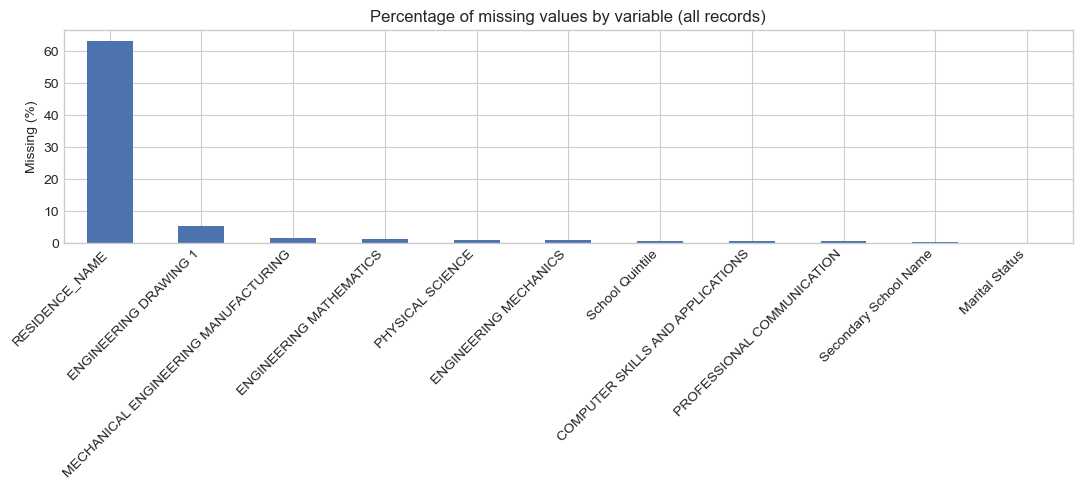

Complete-case exclusion: retained vs excluded students


,Measure,Retained (7 modules),Excluded (<7 modules)
0,n,680.0,45.0
1,Mean of available marks,54.3,45.1
2,% with at least one available mark < 50,57.6,66.7
3,% in 2022,17.5,37.8
4,% in 2023,19.9,24.4
5,% in 2024,23.7,4.4
6,% in 2025,39.0,33.3


A missing mark can never count as a failure, so the risk status of excluded students is understated/unknown. All failure rates below are therefore conditional on being registered for all 7 modules (see the limitations section).


In [ ]:
# missing values 
miss = pd.DataFrame({"Missing": df_raw.isnull().sum(), "Percent": df_raw.isnull().mean() * 100})
miss = miss[miss["Missing"] > 0].sort_values("Percent", ascending=False)
save_table("T_missing_values", miss.round(2).reset_index().rename(columns={"index": "Variable"}))
if len(miss):
    ax = miss["Percent"].plot(kind="bar", figsize=(11, 5), color="#4c72b0")
    ax.set_title("Percentage of missing values by variable (all records)")
    ax.set_ylabel("Missing (%)"); ax.set_xlabel("")
    plt.xticks(rotation=45, ha="right"); plt.tight_layout()
    finish_fig("F_missing_values")

#  who is excluded by the complete-case rule? (selection-bias check) 
def profile(d):
    avail = d[MODULES]
    return pd.Series({
        "n": len(d),
        "Mean of available marks": avail.stack().mean(),
        "% with at least one available mark < 50": (avail.lt(PASS_MARK).any(axis=1)).mean() * 100,
        **{f"% in {int(y)}": (d["Academic Year"] == y).mean() * 100 for y in sorted(df_raw["Academic Year"].unique())},
    })
sel = pd.DataFrame({"Retained (7 modules)": profile(df_raw.loc[complete]),
                    "Excluded (<7 modules)": profile(dropped)}).round(1)
print("Complete-case exclusion: retained vs excluded students")
save_table("T_exclusion_check", sel.reset_index().rename(columns={"index": "Measure"}))
print("A missing mark can never count as a failure, so the risk status of excluded students is understated/unknown. "
      "All failure rates below are therefore conditional on being registered for all 7 modules (see the limitations section).")

In [ ]:
# keep ONLY the analysis columns; everything else is documented, not silently dropped 
unused = [c for c in df_cc.columns if c not in ALL_FEATURES + ["Academic Year", "Identifier", "At_Risk",
                                                                "At_Risk_derived", "At_Risk_file"]]
print("Columns present in the file but not used (documented):")
print("  ", unused)
absent = [c for c in ALL_FEATURES if c not in df_cc.columns]
if absent:
    raise KeyError(f"Feature columns missing from the data: {absent}")

keep = ["Identifier", "Academic Year", "At_Risk"] + ALL_FEATURES + (["At_Risk_file"] if "At_Risk_file" in df_cc.columns else [])
df_cc = df_cc[keep].copy()
print("Analysis frame:", df_cc.shape)

exc = pd.DataFrame({"Excluded column": list(EXCLUDED), "Reason": list(EXCLUDED.values())})
save_table("T_excluded_columns", exc, show=False)

feat_tbl = pd.DataFrame({"Feature": ALL_FEATURES,
    "Type": ["numeric"] * len(NUMERIC_FEATURES) + ["binary"] * len(BINARY_FEATURES) + ["nominal (one-hot)"] * len(NOMINAL_FEATURES),
    "Known at registration?": ["no (final mark)" if f in MODULES else "yes" for f in ALL_FEATURES]})
save_table("T_feature_list", feat_tbl)

Columns present in the file but not used (documented):
   ['Faculty', 'Department Name', 'Birthdate', 'Qualification Code', 'Qualification Name', 'Offering Type', 'Campus Name', 'Period Of Study', 'Ften Status This Year', 'Marital Status', 'Matric Type', 'Secondary School Name', 'Qualification Type', 'Post Graduate', 'Formal Time', 'Bursary Type', 'Average Marks', 'RESIDENCE_NAME', 'Downstream_Outcome']
Analysis frame: (680, 22)


,Feature,Type,Known at registration?
0,COMPUTER SKILLS AND APPLICATIONS,numeric,no (final mark)
1,ENGINEERING DRAWING 1,numeric,no (final mark)
2,ENGINEERING MATHEMATICS,numeric,no (final mark)
3,ENGINEERING MECHANICS,numeric,no (final mark)
4,MECHANICAL ENGINEERING MANUFACTURING,numeric,no (final mark)
5,PHYSICAL SCIENCE,numeric,no (final mark)
6,PROFESSIONAL COMMUNICATION,numeric,no (final mark)
7,School Quintile,numeric,yes
8,Age_at_Registration,numeric,yes
9,Gender,binary,yes


## 3. Exploratory data analysis

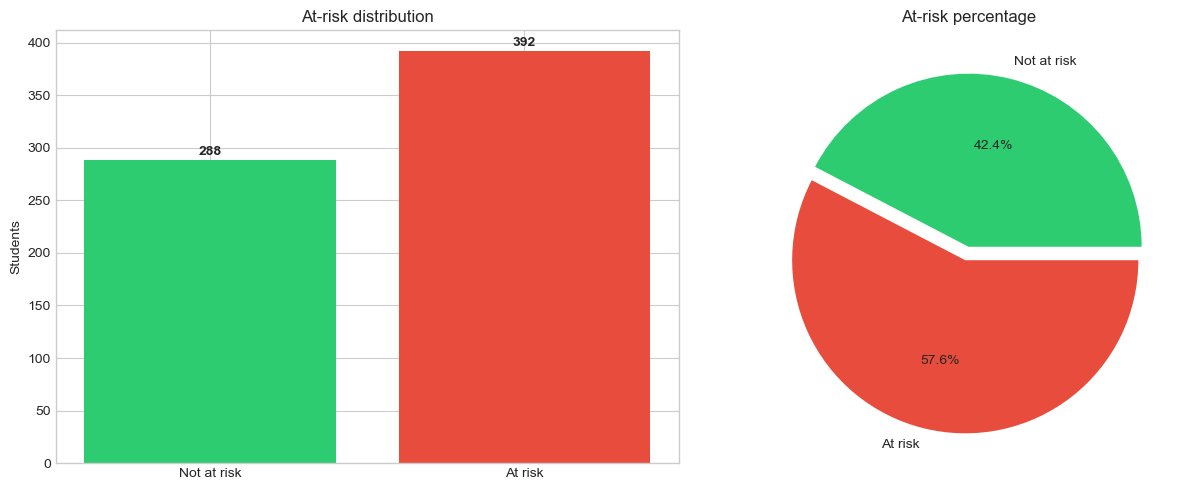

Not at risk: 288 (42.4%) | At risk: 392 (57.6%)
Majority-class baseline accuracy = 0.576


In [6]:
# target distribution
counts = df_cc["At_Risk"].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(["Not at risk", "At risk"], counts.values, color=["#2ecc71", "#e74c3c"])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 5, str(v), ha="center", fontweight="bold")
axes[0].set_title("At-risk distribution"); axes[0].set_ylabel("Students")
axes[1].pie(counts.values, labels=["Not at risk", "At risk"], autopct="%1.1f%%",
            colors=["#2ecc71", "#e74c3c"], explode=(0, 0.08))
axes[1].set_title("At-risk percentage")
plt.tight_layout(); finish_fig("F_target_distribution")
print(f"Not at risk: {counts[0]} ({counts[0]/len(df_cc)*100:.1f}%) | At risk: {counts[1]} ({counts[1]/len(df_cc)*100:.1f}%)")
print(f"Majority-class baseline accuracy = {counts.max()/len(df_cc):.3f}")

,Variable,count,mean,std,min,25%,50%,75%,max
0,COMPUTER SKILLS AND APPLICATIONS,680.0,60.56,14.60,0.0,56.0,63.0,69.00,89.0
1,ENGINEERING DRAWING 1,680.0,49.48,20.78,0.0,36.0,53.0,64.00,92.0
2,ENGINEERING MATHEMATICS,680.0,48.09,19.32,0.0,35.0,51.0,61.00,91.0
3,ENGINEERING MECHANICS,680.0,53.29,15.92,0.0,44.0,55.0,64.00,87.0
4,MECHANICAL ENGINEERING MANUFACTURING,680.0,55.85,14.48,0.0,50.0,57.0,65.00,84.0
5,PHYSICAL SCIENCE,680.0,54.82,13.56,0.0,50.0,57.0,63.00,81.0
6,PROFESSIONAL COMMUNICATION,680.0,58.29,12.61,0.0,53.0,60.0,66.25,83.0
7,School Quintile,674.0,3.26,1.38,1.0,2.0,3.0,5.00,5.0
8,Age_at_Registration,680.0,18.99,1.77,17.0,18.0,19.0,20.00,33.0


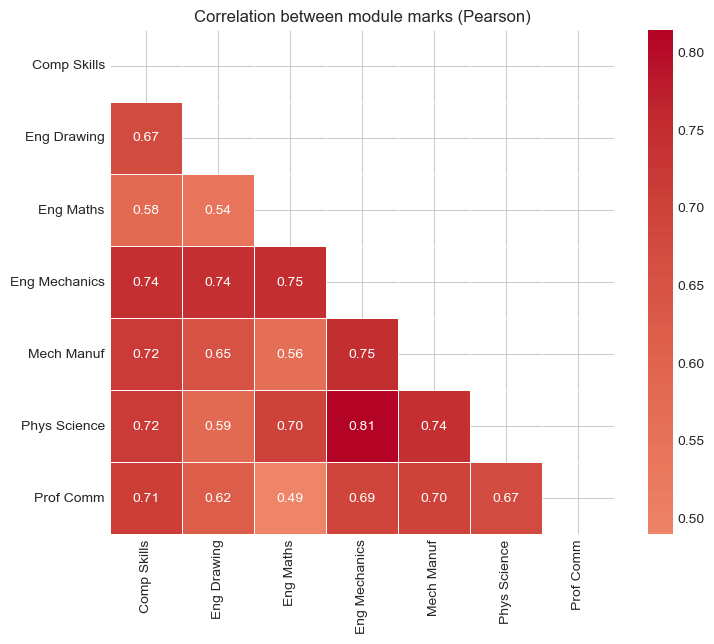

Largest absolute pairwise correlation between modules: 0.81


In [7]:
# numeric summary + correlation (marks and numeric background variables)
num_cols = MODULES + ["School Quintile", "Age_at_Registration"]
save_table("T_numeric_summary", df_cc[num_cols].describe().T.round(2).reset_index().rename(columns={"index": "Variable"}))

corr = df_cc[MODULES].rename(columns=SHORT).corr()
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), cmap="coolwarm", center=0,
            annot=True, fmt=".2f", square=True, linewidths=0.5)
plt.title("Correlation between module marks (Pearson)")
plt.tight_layout(); finish_fig("F_mark_correlation")
off = corr.where(~np.eye(len(corr), dtype=bool)).abs()
print(f"Largest absolute pairwise correlation between modules: {np.nanmax(off.values):.2f}")

In [8]:
# Association with risk status, as described in the Methods chapter:
#   categorical -> chi-square test of independence (+ Cramer's V, + check of expected counts)
#   numeric     -> Mann-Whitney U (+ rank-biserial correlation)
# Holm adjustment because ~15 tests are run.
def association_table(df, target="At_Risk"):
    rows = []
    cat_vars = BINARY_FEATURES + NOMINAL_FEATURES + ["Academic Year"]
    for c in cat_vars:
        s = df[c].fillna("Missing").astype(str)
        vc = s.value_counts()
        s = s.where(~s.isin(vc[vc < MIN_CAT_FREQ].index), "Other (<5)")      # pool tiny categories
        ct = pd.crosstab(s, df[target])
        if ct.shape[0] < 2:
            continue
        chi, p, dof, exp = stats.chi2_contingency(ct)
        k = min(ct.shape) - 1
        rows.append({"Variable": c, "Test": "Chi-square", "Levels": ct.shape[0], "Statistic": chi, "df": dof,
                     "p-value": p, "Effect size": np.sqrt(chi / (ct.values.sum() * k)), "Effect measure": "Cramer's V",
                     "% cells expected <5": (exp < 5).mean() * 100})
    for c in MODULES + ["School Quintile", "Age_at_Registration"]:
        a = df.loc[df[target] == 1, c].dropna(); b = df.loc[df[target] == 0, c].dropna()
        u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
        rows.append({"Variable": c, "Test": "Mann-Whitney U", "Levels": np.nan, "Statistic": u, "df": np.nan,
                     "p-value": p, "Effect size": 2 * u / (len(a) * len(b)) - 1, "Effect measure": "rank-biserial (+ = higher in at-risk)",
                     "% cells expected <5": np.nan})
    out = pd.DataFrame(rows)
    out["p (Holm)"] = multipletests(out["p-value"], method="holm")[1]
    out["Significant (Holm, 0.05)"] = np.where(out["p (Holm)"] < 0.05, "yes", "no")
    return out.sort_values("p-value").reset_index(drop=True)

assoc = association_table(df_cc)
save_table("T_association_tests", assoc.round(4))
print("NOTE: the mark variables differ between groups BY CONSTRUCTION (at risk = at least one mark < 50). "
      "The informative rows are the background variables.")

,Variable,Test,Levels,Statistic,df,p-value,Effect size,Effect measure,% cells expected <5,p (Holm),"Significant (Holm, 0.05)"
0,ENGINEERING MECHANICS,Mann-Whitney U,NaN,10927.0000,NaN,0.0000,-0.8064,rank-biserial (+ = higher in at-risk),NaN,0.0000,yes
1,ENGINEERING MATHEMATICS,Mann-Whitney U,NaN,11480.0000,NaN,0.0000,-0.7966,rank-biserial (+ = higher in at-risk),NaN,0.0000,yes
2,PHYSICAL SCIENCE,Mann-Whitney U,NaN,13265.0000,NaN,0.0000,-0.7650,rank-biserial (+ = higher in at-risk),NaN,0.0000,yes
3,ENGINEERING DRAWING 1,Mann-Whitney U,NaN,14674.0000,NaN,0.0000,-0.7400,rank-biserial (+ = higher in at-risk),NaN,0.0000,yes
4,MECHANICAL ENGINEERING MANUFACTURING,Mann-Whitney U,NaN,21679.5000,NaN,0.0000,-0.6159,rank-biserial (+ = higher in at-risk),NaN,0.0000,yes
5,COMPUTER SKILLS AND APPLICATIONS,Mann-Whitney U,NaN,22267.5000,NaN,0.0000,-0.6055,rank-biserial (+ = higher in at-risk),NaN,0.0000,yes
6,PROFESSIONAL COMMUNICATION,Mann-Whitney U,NaN,26793.5000,NaN,0.0000,-0.5253,rank-biserial (+ = higher in at-risk),NaN,0.0000,yes
7,School Quintile,Mann-Whitney U,NaN,45321.5000,NaN,0.0000,-0.1832,rank-biserial (+ = higher in at-risk),NaN,0.0004,yes
8,Language Name,Chi-square,14.0,33.0202,13.0,0.0017,0.2204,Cramer's V,10.7143,0.0186,yes
9,FUNDNAME,Chi-square,6.0,17.8822,5.0,0.0031,0.1622,Cramer's V,33.3333,0.0310,yes


NOTE: the mark variables differ between groups BY CONSTRUCTION (at risk = at least one mark < 50). The informative rows are the background variables.


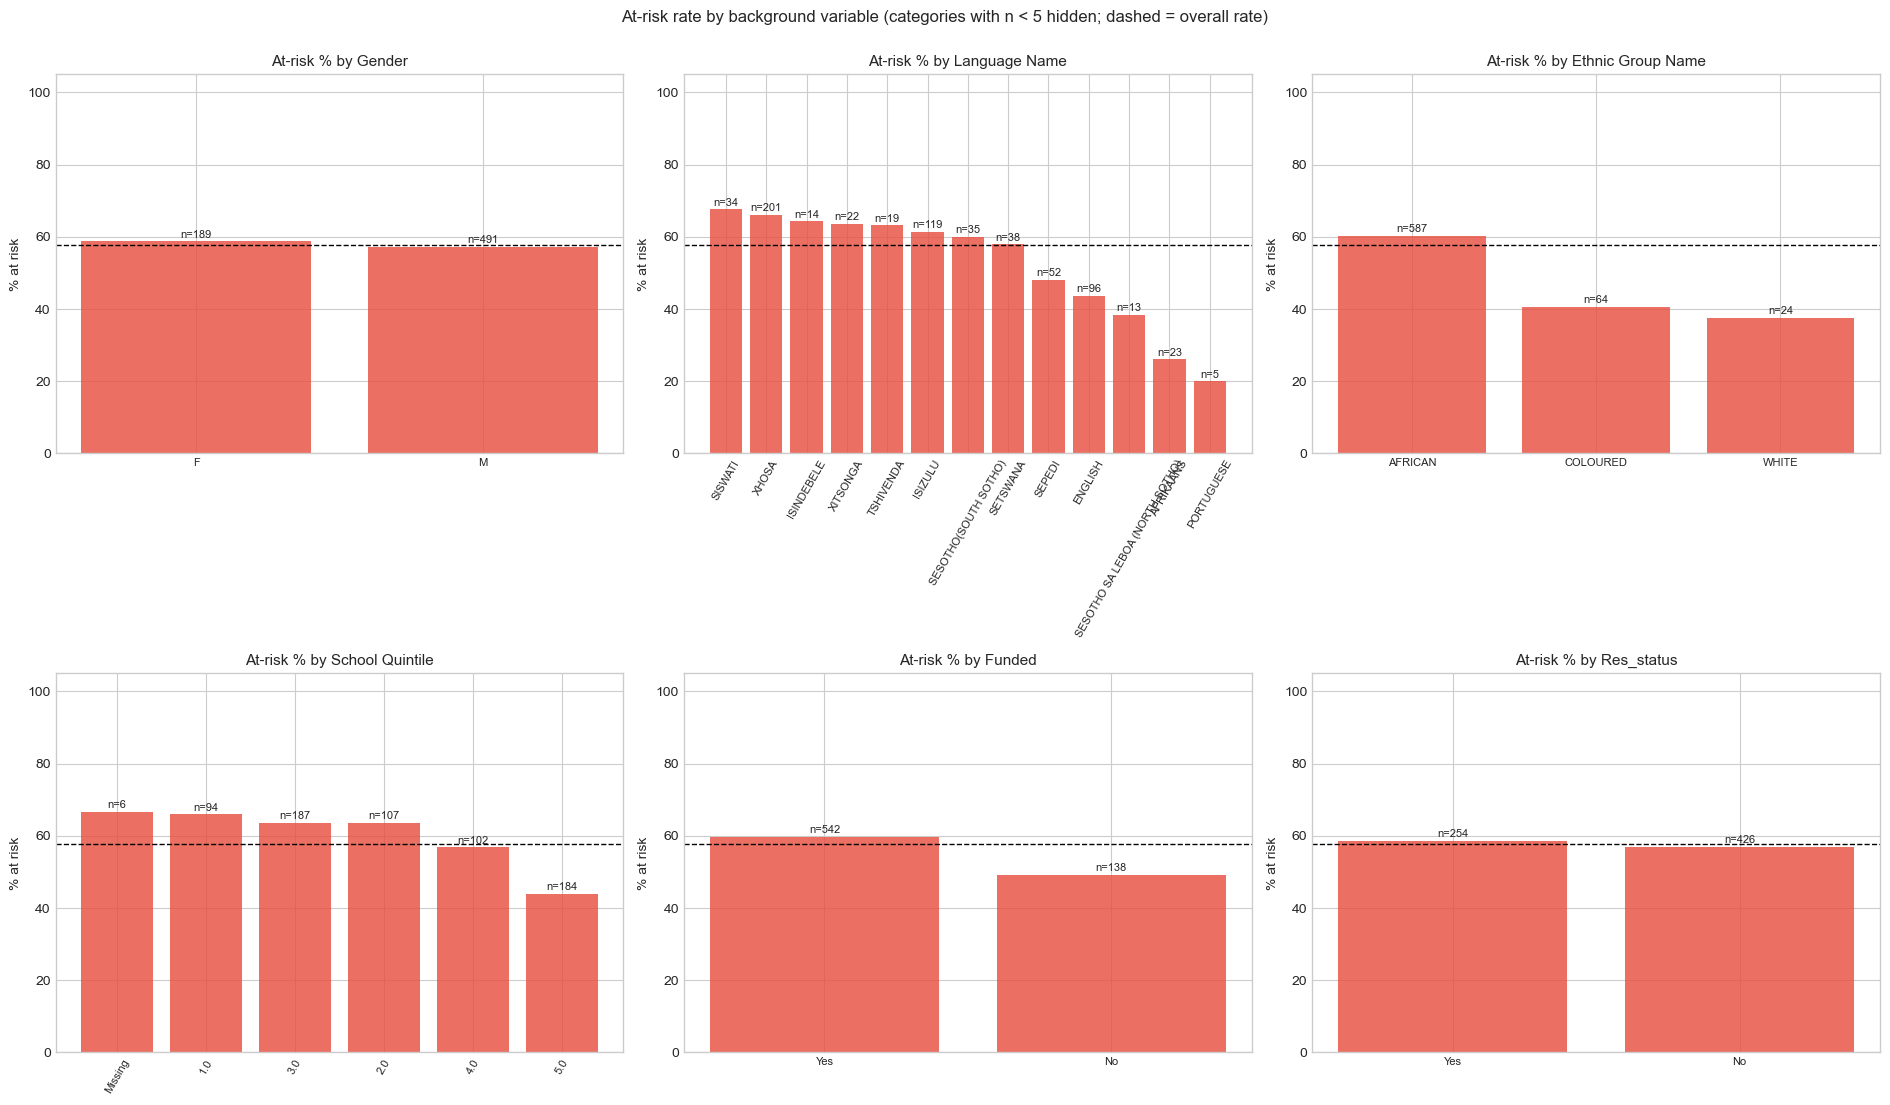

In [9]:
# at-risk rate by background variable (percent of each category that is at risk)
demo = ["Gender", "Language Name", "Ethnic Group Name", "School Quintile", "Funded", "Res_status"]
fig, axes = plt.subplots(2, 3, figsize=(19, 11))
for ax, col in zip(axes.ravel(), demo):
    tab = df_cc.groupby(df_cc[col].fillna("Missing").astype(str))["At_Risk"].agg(["mean", "size"])
    tab = tab[tab["size"] >= MIN_CAT_FREQ].sort_values("mean", ascending=False)
    ax.bar(tab.index, tab["mean"] * 100, color="#e74c3c", alpha=0.8)
    for i, (m, n) in enumerate(zip(tab["mean"], tab["size"])):
        ax.text(i, m * 100 + 1, f"n={n}", ha="center", fontsize=8)
    ax.axhline(df_cc["At_Risk"].mean() * 100, color="k", ls="--", lw=1)
    ax.set_title(f"At-risk % by {col}", fontsize=11); ax.set_ylim(0, 105); ax.set_ylabel("% at risk")
    ax.tick_params(axis="x", rotation=60 if len(tab) > 4 else 0, labelsize=8)
plt.suptitle("At-risk rate by background variable (categories with n < 5 hidden; dashed = overall rate)", y=1.0)
plt.tight_layout(); finish_fig("F_risk_by_background")

,Academic Year,n,at_risk,% at risk,95% CI lower,95% CI upper
0,2022,119,70,58.8,49.8,67.3
1,2023,135,73,54.1,45.7,62.3
2,2024,161,95,59.0,51.3,66.3
3,2025,265,154,58.1,52.1,63.9


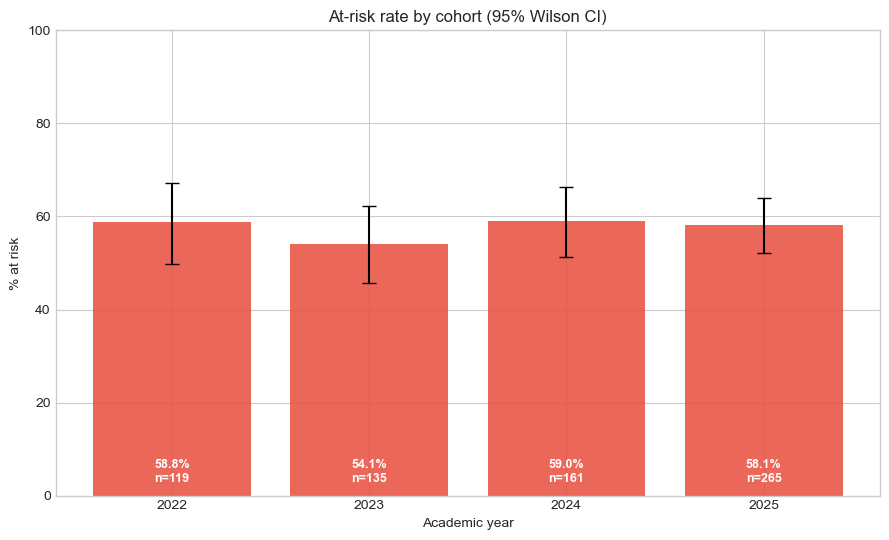

Chi-square test of at-risk rate across cohorts: chi2 = 0.92, p = 0.821


In [10]:
# at-risk by academic year (with cohort sizes)
yr = df_cc.groupby("Academic Year")["At_Risk"].agg(n="size", at_risk="sum")
yr["% at risk"] = (yr["at_risk"] / yr["n"] * 100).round(1)
lo_hi = [wilson(k, n) for k, n in zip(yr["at_risk"], yr["n"])]
yr["95% CI lower"] = [round(x[0], 1) for x in lo_hi]; yr["95% CI upper"] = [round(x[1], 1) for x in lo_hi]
save_table("T_risk_by_year", yr.reset_index())

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.bar(yr.index.astype(str), yr["% at risk"], color="#e74c3c", alpha=0.85,
       yerr=[yr["% at risk"] - yr["95% CI lower"], yr["95% CI upper"] - yr["% at risk"]], capsize=5)
for i, (p, n) in enumerate(zip(yr["% at risk"], yr["n"])):
    ax.text(i, 3, f"{p}%\nn={n}", ha="center", color="white", fontsize=9, fontweight="bold")
ax.set_ylim(0, 100); ax.set_ylabel("% at risk"); ax.set_xlabel("Academic year")
ax.set_title("At-risk rate by cohort (95% Wilson CI)")
plt.tight_layout(); finish_fig("F_risk_by_year")
chi, p, *_ = stats.chi2_contingency(pd.crosstab(df_cc["Academic Year"], df_cc["At_Risk"]))
print(f"Chi-square test of at-risk rate across cohorts: chi2 = {chi:.2f}, p = {p:.3f}")

## 4. Train / test split and pipelines
All preprocessing (imputation, scaling, encoding, feature selection) lives **inside** each `Pipeline`, so it is re-fitted on the training folds only during cross-validation. The old notebook fitted the preprocessor on the full training set first and then cross-validated, which leaks information from validation folds.

In [11]:
X_all, y_all, cohort = df_cc[ALL_FEATURES], df_cc["At_Risk"], df_cc["Academic Year"]

# stratify on the target only (same split as the original notebook: same seed, same test size)
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=TEST_SIZE,
                                                    random_state=RANDOM_STATE, stratify=y_all)
print(f"Train: {len(X_train)} | Test: {len(X_test)}")
print("Train at-risk share:", round(y_train.mean(), 3), "| Test at-risk share:", round(y_test.mean(), 3))
print("Test set composition: at risk =", int(y_test.sum()), "| not at risk =", int((y_test == 0).sum()))
KEY.update(n_train=len(X_train), n_test=len(X_test), test_at_risk=int(y_test.sum()), test_not_at_risk=int((y_test == 0).sum()))

def make_preprocessor(features, scale):
    num = [c for c in NUMERIC_FEATURES if c in features]
    binf = [c for c in BINARY_FEATURES if c in features]
    nom = [c for c in NOMINAL_FEATURES if c in features]
    tr = []
    if num:
        steps = [("imputer", SimpleImputer(strategy="median"))] + ([("scaler", StandardScaler())] if scale else [])
        tr.append(("num", Pipeline(steps), num))
    if binf:
        tr.append(("binary", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                       ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))]), binf))
    if nom:
        tr.append(("nominal", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                        ("encoder", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                                  min_frequency=MIN_CAT_FREQ, sparse_output=False))]), nom))
    return ColumnTransformer(tr, remainder="drop")

SVM_DEFAULT = dict(kernel="rbf", C=1.0, gamma="scale")
RF_DEFAULT  = dict(n_estimators=200, max_depth=10, min_samples_split=10, min_samples_leaf=5)

def make_svm(features, **params):
    return Pipeline([("preprocess", make_preprocessor(features, scale=True)),
                     ("classifier", SVC(probability=True, class_weight="balanced", random_state=RANDOM_STATE,
                                        **{**SVM_DEFAULT, **params}))])

def make_rf(features, **params):
    return Pipeline([("preprocess", make_preprocessor(features, scale=False)),
                     ("classifier", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE,
                                                           n_jobs=1, **{**RF_DEFAULT, **params}))])

def make_svm_fs(features, k=20, **params):
    # chi-square filter INSIDE the pipeline (k is tuned by CV, not picked on the same data it is evaluated on)
    return Pipeline([("preprocess", make_preprocessor(features, scale=True)),
                     ("minmax", MinMaxScaler()),
                     ("select", SelectKBest(chi2, k=k)),
                     ("classifier", SVC(probability=True, class_weight="balanced", random_state=RANDOM_STATE,
                                        **{**SVM_DEFAULT, **params}))])

SCORING = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}
CV_STRAT  = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
CV_REPEAT = RepeatedStratifiedKFold(n_splits=CV_FOLDS, n_repeats=CV_REPEATS, random_state=RANDOM_STATE)

Train: 544 | Test: 136
Train at-risk share: 0.577 | Test at-risk share: 0.574
Test set composition: at risk = 78 | not at risk = 58


## 5. Baselines — what does a "model" have to beat?
The target is *defined* from the seven marks (at risk = any mark below 50) and those marks are also features. A one-line rule therefore reproduces the target exactly. This is the leakage problem discussed in the dissertation review; the rule is the honest benchmark for any model that uses the marks.

In [12]:
def metrics_from(y_true, y_pred, y_score=None):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    out = {"Accuracy": accuracy_score(y_true, y_pred),
           "Precision": precision_score(y_true, y_pred, zero_division=0),
           "Recall": recall_score(y_true, y_pred, zero_division=0),
           "F1": f1_score(y_true, y_pred, zero_division=0),
           "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
           "ROC-AUC": roc_auc_score(y_true, y_score) if y_score is not None else np.nan,
           "TN": tn, "FP": fp, "FN": fn, "TP": tp}
    return out

def boot_ci(y_true, y_pred, fn, n=N_BOOT, seed=RANDOM_STATE):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n):
        b = rng.integers(0, len(y_true), len(y_true))
        if y_true[b].sum() == 0 or (y_true[b] == 0).sum() == 0:
            continue
        vals.append(fn(y_true[b], y_pred[b]))
    return np.percentile(vals, [2.5, 97.5])

BASELINES = {}
# 1. majority class
dm = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
BASELINES["Majority class (always 'at risk')"] = (dm.predict(X_test), dm.predict_proba(X_test)[:, 1])
# 2. coin-flip proportional to class balance
ds = DummyClassifier(strategy="stratified", random_state=RANDOM_STATE).fit(X_train, y_train)
BASELINES["Random (class proportions)"] = (ds.predict(X_test), ds.predict_proba(X_test)[:, 1])
# 3. the leakage rule: no learning at all
rule_pred = (X_test[MODULES] < PASS_MARK).any(axis=1).astype(int).values
BASELINES[f"Rule: any module mark < {PASS_MARK} (no model)"] = (rule_pred, rule_pred.astype(float))

base_rows = []
for name, (yp, ys) in BASELINES.items():
    m = metrics_from(y_test, yp, ys); m["Model"] = name; base_rows.append(m)
baseline_df = pd.DataFrame(base_rows).set_index("Model")
display(baseline_df.round(4))
assert metrics_from(y_test, rule_pred)["Accuracy"] == 1.0, (
    "The rule should reproduce the target exactly; if not, the target definition and marks disagree - investigate.")
print("The rule reproduces the target with 100% accuracy: any model using the marks is re-learning the pass mark.")

,Accuracy,Precision,Recall,F1,Specificity,ROC-AUC,TN,FP,FN,TP
Model,,,,,,,,,,
Majority class (always 'at risk'),0.5735,0.5735,1.0000,0.729,0.0000,0.5000,0,58,0,78
Random (class proportions),0.5294,0.5854,0.6154,0.600,0.4138,0.5146,24,34,30,48
Rule: any module mark < 50 (no model),1.0000,1.0000,1.0000,1.000,1.0000,1.0000,58,0,0,78


The rule reproduces the target with 100% accuracy: any model using the marks is re-learning the pass mark.


## 6. Hyper-parameter tuning (training data only)
Tuning uses stratified 5-fold CV **inside the training set**; the test set is never touched. 

In [13]:
tuned = {}
if RUN_TUNING:
    grids = {
        "SVM":    (make_svm(ALL_FEATURES),    {"classifier__C": [0.1, 1, 10, 100], "classifier__gamma": ["scale", 0.01, 0.03, 0.1]}),
        "RF":     (make_rf(ALL_FEATURES),     {"classifier__n_estimators": [200, 500], "classifier__max_depth": [5, 10, None],
                                               "classifier__min_samples_leaf": [1, 3, 5]}),
        "SVM+FS": (make_svm_fs(ALL_FEATURES), {"select__k": [10, 15, 20, 25, 30], "classifier__C": [1, 10]}),
    }
    rows = []
    for key, (pipe, grid) in grids.items():
        t0 = time.time()
        gs = GridSearchCV(pipe, grid, scoring=TUNE_SCORING, cv=CV_STRAT, n_jobs=-1, refit=True)
        gs.fit(X_train, y_train)
        tuned[key] = gs
        rows.append({"Model": key, "Best params": {k.split("__")[1]: v for k, v in gs.best_params_.items()},
                     f"Best CV {TUNE_SCORING}": round(gs.best_score_, 4), "Seconds": round(time.time() - t0, 1)})
    tune_df = pd.DataFrame(rows)
    tune_df["Best params"] = tune_df["Best params"].astype(str)
    save_table("T_tuning_results", tune_df)
else:
    print("Tuning skipped.")

,Model,Best params,Best CV f1,Seconds
0,SVM,"{'C': 1, 'gamma': 0.1}",0.9401,45.5
1,RF,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",0.9750,34.6
2,SVM+FS,"{'C': 10, 'k': 10}",0.9407,2.7


In [14]:
# Build every candidate. 'default' = the fixed settings used in the original notebook.
def tuned_params(key, prefix="classifier__"):
    return {k.split("__")[1]: v for k, v in tuned[key].best_params_.items() if k.startswith(prefix)}

CANDIDATES = {
    "SVM (default)":              make_svm(ALL_FEATURES),
    "Random Forest (default)":    make_rf(ALL_FEATURES),
    "SVM + chi-square selection": (tuned["SVM+FS"].best_estimator_ if RUN_TUNING else make_svm_fs(ALL_FEATURES)),
    "SVM (background only)":      make_svm(BACKGROUND_FEATURES),
    "Random Forest (background only)": make_rf(BACKGROUND_FEATURES),
}
if RUN_TUNING:
    CANDIDATES["SVM (tuned)"] = tuned["SVM"].best_estimator_
    CANDIDATES["Random Forest (tuned)"] = tuned["RF"].best_estimator_
FEATS_OF = {n: (BACKGROUND_FEATURES if "background" in n else ALL_FEATURES) for n in CANDIDATES}

fitted, PRED, CVRES = {}, {}, {}
rows = []
for name, model in CANDIDATES.items():
    feats = FEATS_OF[name]
    m = clone(model).fit(X_train[feats], y_train) if not (RUN_TUNING and name in ("SVM (tuned)", "Random Forest (tuned)", "SVM + chi-square selection")) else model
    fitted[name] = m
    yp = m.predict(X_test[feats]); ys = m.predict_proba(X_test[feats])[:, 1]
    PRED[name] = (yp, ys)
    res = metrics_from(y_test, yp, ys)
    ci_rec = boot_ci(y_test, yp, lambda a, b: recall_score(a, b, zero_division=0))
    ci_pre = boot_ci(y_test, yp, lambda a, b: precision_score(a, b, zero_division=0))
    ci_acc = boot_ci(y_test, yp, accuracy_score)
    cv = cross_validate(clone(model), X_train[feats], y_train, cv=CV_REPEAT, scoring=SCORING, n_jobs=-1)
    CVRES[name] = cv
    rows.append({"Model": name, "Features": "background only" if "background" in name else "marks + background",
                 "Accuracy": res["Accuracy"], "Precision": res["Precision"], "Recall": res["Recall"], "F1": res["F1"],
                 "ROC-AUC": res["ROC-AUC"],
                 "Recall 95% CI (test)": f"{ci_rec[0]:.3f}-{ci_rec[1]:.3f}",
                 "Precision 95% CI (test)": f"{ci_pre[0]:.3f}-{ci_pre[1]:.3f}",
                 "Accuracy 95% CI (test)": f"{ci_acc[0]:.3f}-{ci_acc[1]:.3f}",
                 "CV recall (mean)": cv["test_recall"].mean(), "CV recall (SD)": cv["test_recall"].std(),
                 "CV F1 (mean)": cv["test_f1"].mean(), "CV ROC-AUC (mean)": cv["test_roc_auc"].mean(),
                 "TN": res["TN"], "FP": res["FP"], "FN": res["FN"], "TP": res["TP"]})

comparison = pd.DataFrame(rows).set_index("Model")
num_cols_c = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "CV recall (mean)", "CV recall (SD)", "CV F1 (mean)", "CV ROC-AUC (mean)"]
comparison[num_cols_c] = comparison[num_cols_c].round(4)
save_table("T_model_comparison", comparison.reset_index())
print(f"CV = {CV_FOLDS}-fold stratified, repeated {CV_REPEATS}x, on the training set only. "
      f"Test set: {len(y_test)} students ({int(y_test.sum())} at risk) -> wide confidence intervals.")

,Model,Features,Accuracy,Precision,Recall,F1,ROC-AUC,Recall 95% CI (test),Precision 95% CI (test),Accuracy 95% CI (test),CV recall (mean),CV recall (SD),CV F1 (mean),CV ROC-AUC (mean),TN,FP,FN,TP
0,SVM (default),marks + background,0.8971,0.9706,0.8462,0.9041,0.9819,0.757-0.923,0.925-1.000,0.845-0.949,0.9119,0.0347,0.9350,0.9833,56,2,12,66
1,Random Forest (default),marks + background,0.9706,0.9868,0.9615,0.9740,0.9916,0.914-1.000,0.958-1.000,0.941-0.993,0.9703,0.0260,0.9636,0.9934,57,1,3,75
2,SVM + chi-square selection,marks + background,0.9485,0.9733,0.9359,0.9542,0.9828,0.875-0.987,0.931-1.000,0.904-0.985,0.9119,0.0332,0.9380,0.9841,56,2,5,73
3,SVM (background only),background only,0.5809,0.6522,0.5769,0.6122,0.6120,0.462-0.679,0.538-0.768,0.493-0.662,0.6540,0.0589,0.6381,0.5970,34,24,33,45
4,Random Forest (background only),background only,0.5956,0.6456,0.6538,0.6497,0.5924,0.545-0.750,0.542-0.747,0.507-0.676,0.6645,0.0437,0.6453,0.5921,30,28,27,51
5,SVM (tuned),marks + background,0.8971,0.9706,0.8462,0.9041,0.9841,0.757-0.923,0.925-1.000,0.845-0.949,0.9236,0.0314,0.9404,0.9837,56,2,12,66
6,Random Forest (tuned),marks + background,0.9632,0.9740,0.9615,0.9677,0.9943,0.914-1.000,0.936-1.000,0.926-0.993,0.9852,0.0136,0.9743,0.9964,56,2,3,75


CV = 5-fold stratified, repeated 3x, on the training set only. Test set: 136 students (78 at risk) -> wide confidence intervals.


In [15]:
# Which configuration do the downstream sections use?
sfx = FINAL_CONFIG
svm_final, rf_final = fitted[f"SVM ({sfx})"], fitted[f"Random Forest ({sfx})"]
svm_name, rf_name = f"SVM ({sfx})", f"Random Forest ({sfx})"

# Primary model chosen on CROSS-VALIDATED recall (training data), not on the test set.
cv_rec = {n: CVRES[n]["test_recall"].mean() for n in (svm_name, rf_name)}
PRIMARY = max(cv_rec, key=cv_rec.get)
print("CV recall:", {k: round(v, 4) for k, v in cv_rec.items()})
print(f"Primary model by the stated rule (highest cross-validated recall): {PRIMARY}")
print("\nIMPORTANT: for the marks-based models, compare with the rule baseline above. "
      "The background-only rows are the only models that could work as an early warning.")
KEY.update(final_config=FINAL_CONFIG, primary_model=PRIMARY)
for n in (svm_name, rf_name):
    r = comparison.loc[n]
    KEY[n] = {k: (float(r[k]) if k in ("Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "CV recall (mean)") else int(r[k]))
              for k in ("Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "CV recall (mean)", "TN", "FP", "FN", "TP")}

CV recall: {'SVM (tuned)': np.float64(0.9236), 'Random Forest (tuned)': np.float64(0.9852)}
Primary model by the stated rule (highest cross-validated recall): Random Forest (tuned)

IMPORTANT: for the marks-based models, compare with the rule baseline above. The background-only rows are the only models that could work as an early warning.


## 7. Diagnostics for the two final models

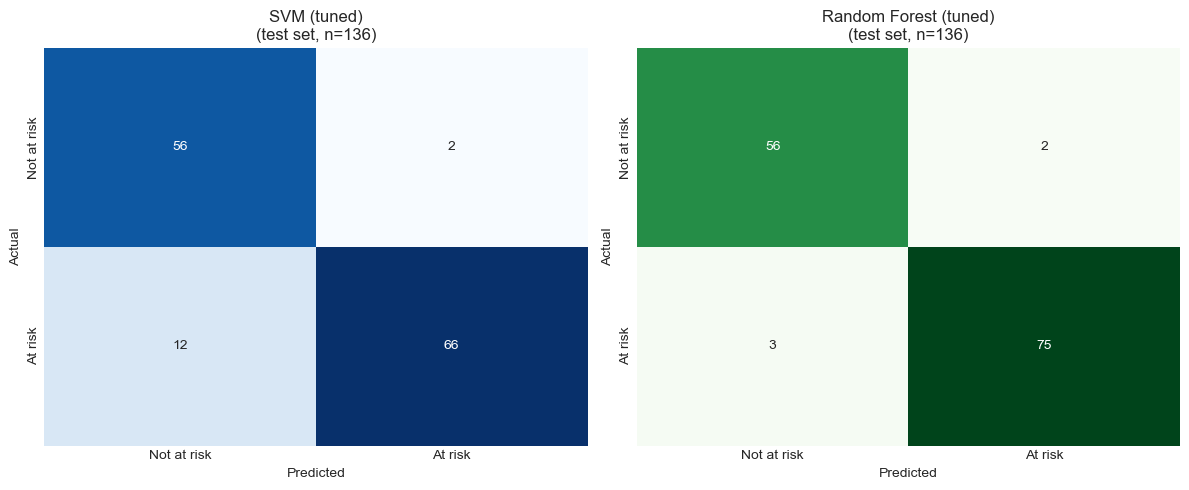

SVM (tuned): TP=66 FN=12 FP=2 TN=56 | recall=0.8462 precision=0.9706
Random Forest (tuned): TP=75 FN=3 FP=2 TN=56 | recall=0.9615 precision=0.9740


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name, cmap in zip(axes, (svm_name, rf_name), ("Blues", "Greens")):
    cm = confusion_matrix(y_test, PRED[name][0], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, cbar=False, ax=ax,
                xticklabels=["Not at risk", "At risk"], yticklabels=["Not at risk", "At risk"])
    ax.set_title(f"{name}\n(test set, n={len(y_test)})"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); finish_fig("F_confusion_matrices")
for n in (svm_name, rf_name):
    tn, fp, fn, tp = confusion_matrix(y_test, PRED[n][0], labels=[0, 1]).ravel()
    print(f"{n}: TP={tp} FN={fn} FP={fp} TN={tn} | recall={tp/(tp+fn):.4f} precision={tp/(tp+fp) if tp+fp else float('nan'):.4f}")

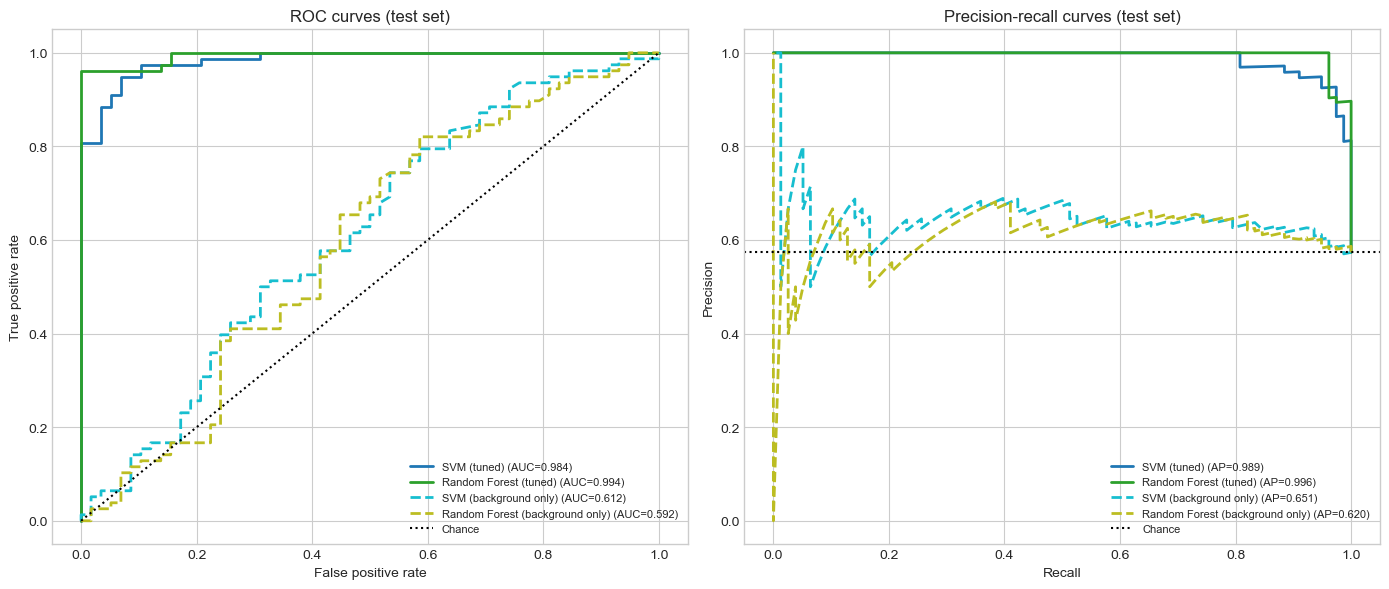

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for name, col in ((svm_name, "tab:blue"), (rf_name, "tab:green"),
                  ("SVM (background only)", "tab:cyan"), ("Random Forest (background only)", "tab:olive")):
    ys = PRED[name][1]
    fpr, tpr, _ = roc_curve(y_test, ys)
    axes[0].plot(fpr, tpr, lw=2, color=col, ls="--" if "background" in name else "-",
                 label=f"{name} (AUC={roc_auc_score(y_test, ys):.3f})")
    p, r, _ = precision_recall_curve(y_test, ys)
    axes[1].plot(r, p, lw=2, color=col, ls="--" if "background" in name else "-",
                 label=f"{name} (AP={average_precision_score(y_test, ys):.3f})")
axes[0].plot([0, 1], [0, 1], "k:", label="Chance"); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curves (test set)"); axes[0].legend(fontsize=8)
axes[1].axhline(y_test.mean(), color="k", ls=":", label="Chance"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curves (test set)"); axes[1].legend(fontsize=8)
plt.tight_layout(); finish_fig("F_roc_pr_curves")

In [18]:
# Is the RF-vs-SVM difference real? McNemar's exact test on the paired test-set predictions.
ok_svm = PRED[svm_name][0] == y_test.values
ok_rf  = PRED[rf_name][0] == y_test.values
tbl = [[int((ok_svm & ok_rf).sum()),  int((ok_svm & ~ok_rf).sum())],
       [int((~ok_svm & ok_rf).sum()), int((~ok_svm & ~ok_rf).sum())]]
mc = mcnemar(tbl, exact=True)
print(f"Both correct: {tbl[0][0]} | only SVM correct: {tbl[0][1]} | only RF correct: {tbl[1][0]} | both wrong: {tbl[1][1]}")
print(f"McNemar exact test p = {mc.pvalue:.4f}  ->  "
      f"{'difference is statistically detectable' if mc.pvalue < 0.05 else 'cannot claim one model is better on this test set'}")
KEY["mcnemar_p_svm_vs_rf"] = float(mc.pvalue)

Both correct: 120 | only SVM correct: 2 | only RF correct: 11 | both wrong: 3
McNemar exact test p = 0.0225  ->  difference is statistically detectable


In [19]:
# Threshold analysis. Recall is the stated priority, so choose the decision threshold using
# OUT-OF-FOLD probabilities on the training set (never the test set), then apply it to the test set.
thr_rows = []
for name in (svm_name, rf_name):
    oof = cross_val_predict(clone(CANDIDATES[name]), X_train, y_train, cv=CV_STRAT, method="predict_proba", n_jobs=-1)[:, 1]
    p, r, t = precision_recall_curve(y_train, oof)
    ok = np.where(r[:-1] >= TARGET_RECALL)[0]
    thr = t[ok[np.argmax(p[:-1][ok])]] if len(ok) else t[np.argmax(r[:-1])]
    ys = PRED[name][1]
    for label, th in (("0.50 (default)", 0.5), (f"{thr:.3f} (recall >= {TARGET_RECALL} in training CV)", thr)):
        yp = (ys >= th).astype(int)
        m = metrics_from(y_test, yp, ys)
        thr_rows.append({"Model": name, "Threshold": label, "Recall": m["Recall"], "Precision": m["Precision"],
                         "False positives": m["FP"], "False negatives": m["FN"], "Accuracy": m["Accuracy"]})
thr_df = pd.DataFrame(thr_rows).round(4)
save_table("T_threshold_analysis", thr_df)

,Model,Threshold,Recall,Precision,False positives,False negatives,Accuracy
0,SVM (tuned),0.50 (default),0.8974,0.9589,3,8,0.9191
1,SVM (tuned),0.401 (recall >= 0.95 in training CV),0.9103,0.9595,3,7,0.9265
2,Random Forest (tuned),0.50 (default),0.9615,0.9740,2,3,0.9632
3,Random Forest (tuned),0.586 (recall >= 0.95 in training CV),0.9487,1.0000,0,4,0.9706


## 8. Feature importance


In [ ]:
def group_of(fname, raw_cols):
    # map an encoded feature name back to its original column
    base = fname.split("__", 1)[1]
    for c in sorted(raw_cols, key=len, reverse=True):
        if base == c or base.startswith(c + "_"):
            return c
    return base

def gini_importance(pipe):
    names = pipe.named_steps["preprocess"].get_feature_names_out()
    imp = pipe.named_steps["classifier"].feature_importances_
    raw = pd.DataFrame({"Encoded feature": names, "Importance": imp})
    raw["Feature"] = [group_of(n, ALL_FEATURES) for n in names]
    return raw.groupby("Feature", as_index=False)["Importance"].sum().sort_values("Importance", ascending=False)

rf_gini = gini_importance(rf_final).reset_index(drop=True)
save_table("T_rf_gini_importance", rf_gini.round(4).head(15))
print("RF Gini importance favours continuous / high-cardinality variables - treat as secondary to permutation importance.")

,Feature,Importance
0,ENGINEERING MATHEMATICS,0.2240
1,ENGINEERING DRAWING 1,0.2236
2,PHYSICAL SCIENCE,0.1502
3,ENGINEERING MECHANICS,0.1492
4,MECHANICAL ENGINEERING MANUFACTURING,0.0680
5,COMPUTER SKILLS AND APPLICATIONS,0.0595
6,PROFESSIONAL COMMUNICATION,0.0532
7,Language Name,0.0206
8,Previous Activity Desc,0.0096
9,Age_at_Registration,0.0091


RF Gini importance favours continuous / high-cardinality variables - treat as secondary to permutation importance.


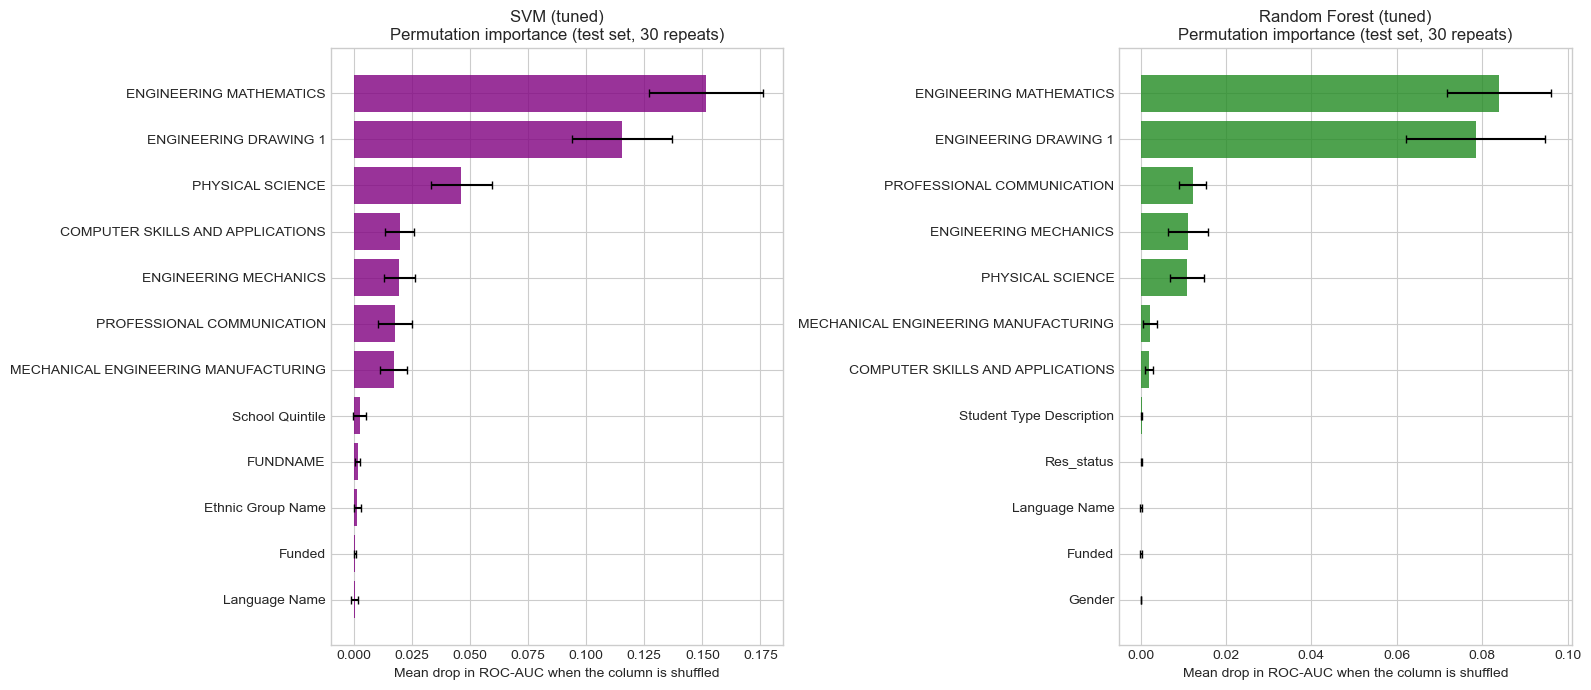

,Feature,Drop in ROC-AUC (SVM),Drop in recall (SVM),Drop in ROC-AUC (RF),Drop in recall (RF)
0,ENGINEERING MATHEMATICS,0.1516,0.0013,0.0840,0.0769
1,ENGINEERING DRAWING 1,0.1154,0.0060,0.0784,0.0692
2,PROFESSIONAL COMMUNICATION,0.0176,-0.0239,0.0122,0.0000
3,ENGINEERING MECHANICS,0.0196,-0.0274,0.0111,0.0026
4,PHYSICAL SCIENCE,0.0463,-0.0350,0.0108,-0.0013
5,MECHANICAL ENGINEERING MANUFACTURING,0.0171,-0.0098,0.0021,-0.0004
6,COMPUTER SKILLS AND APPLICATIONS,0.0197,-0.0214,0.0020,0.0038
7,Student Type Description,-0.0003,-0.0013,0.0002,0.0000
8,Res_status,-0.0005,-0.0103,0.0001,0.0000
9,Language Name,0.0004,-0.0244,0.0001,0.0000


Variables whose shuffling costs > 0.005 AUC in BOTH models: ['ENGINEERING MATHEMATICS', 'ENGINEERING DRAWING 1', 'PROFESSIONAL COMMUNICATION', 'ENGINEERING MECHANICS', 'PHYSICAL SCIENCE']

Module-only importance (mark columns):


,Drop in ROC-AUC (SVM),Drop in recall (SVM),Drop in ROC-AUC (RF),Drop in recall (RF)
Feature,,,,
COMPUTER SKILLS AND APPLICATIONS,0.0197,-0.0214,0.0020,0.0038
ENGINEERING DRAWING 1,0.1154,0.0060,0.0784,0.0692
ENGINEERING MATHEMATICS,0.1516,0.0013,0.0840,0.0769
ENGINEERING MECHANICS,0.0196,-0.0274,0.0111,0.0026
MECHANICAL ENGINEERING MANUFACTURING,0.0171,-0.0098,0.0021,-0.0004
PHYSICAL SCIENCE,0.0463,-0.0350,0.0108,-0.0013
PROFESSIONAL COMMUNICATION,0.0176,-0.0239,0.0122,0.0000


In [21]:
def grouped_permutation(pipe, X, y, name):
    res = permutation_importance(pipe, X[ALL_FEATURES], y, scoring={"roc_auc": "roc_auc", "recall": "recall"},
                                 n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
    out = pd.DataFrame({"Feature": ALL_FEATURES,
                        "Drop in ROC-AUC": res["roc_auc"].importances_mean, "SD (AUC)": res["roc_auc"].importances_std,
                        "Drop in recall": res["recall"].importances_mean, "SD (recall)": res["recall"].importances_std})
    out["Model"] = name
    return out.sort_values("Drop in ROC-AUC", ascending=False).reset_index(drop=True)

perm_svm = grouped_permutation(svm_final, X_test, y_test, svm_name)
perm_rf  = grouped_permutation(rf_final,  X_test, y_test, rf_name)
perm_all = pd.concat([perm_svm, perm_rf], ignore_index=True)
save_table("T_permutation_importance", perm_all.round(4), show=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=False)
for ax, d, col in zip(axes, (perm_svm, perm_rf), ("purple", "forestgreen")):
    top = d.head(12).iloc[::-1]
    ax.barh(top["Feature"], top["Drop in ROC-AUC"], xerr=top["SD (AUC)"], color=col, alpha=0.8, capsize=3)
    ax.set_title(f"{d['Model'].iloc[0]}\nPermutation importance (test set, 30 repeats)")
    ax.set_xlabel("Mean drop in ROC-AUC when the column is shuffled")
plt.tight_layout(); finish_fig("F_permutation_importance")

side = (perm_svm.set_index("Feature")[["Drop in ROC-AUC", "Drop in recall"]].add_suffix(" (SVM)")
        .join(perm_rf.set_index("Feature")[["Drop in ROC-AUC", "Drop in recall"]].add_suffix(" (RF)")))
side = side.sort_values("Drop in ROC-AUC (RF)", ascending=False).round(4)
save_table("T_importance_side_by_side", side.reset_index())

consistent = side[(side["Drop in ROC-AUC (SVM)"] > 0.005) & (side["Drop in ROC-AUC (RF)"] > 0.005)]
print("Variables whose shuffling costs > 0.005 AUC in BOTH models:", list(consistent.index))
mod_imp = side.loc[[m for m in MODULES if m in side.index]]
print("\nModule-only importance (mark columns):")
display(mod_imp)

,Encoded feature,Coefficient
0,num__ENGINEERING MATHEMATICS,-2.2061
1,num__ENGINEERING DRAWING 1,-1.7240
2,num__PHYSICAL SCIENCE,-1.4146
3,nominal__Country Name_infrequent_sklearn,-1.0335
4,nominal__Ethnic Group Name_infrequent_sklearn,0.8662
5,nominal__Ethnic Group Name_AFRICAN,-0.8433
6,nominal__Previous Activity Desc_UNEMPLOYED,0.7119
7,nominal__Country Name_DEMOCRATIC REP OF CONGO,0.7102
8,nominal__Language Name_ISINDEBELE,0.6285
9,nominal__FUNDNAME_FINANCIAL AID GENERIC ACCOUNT,0.5543


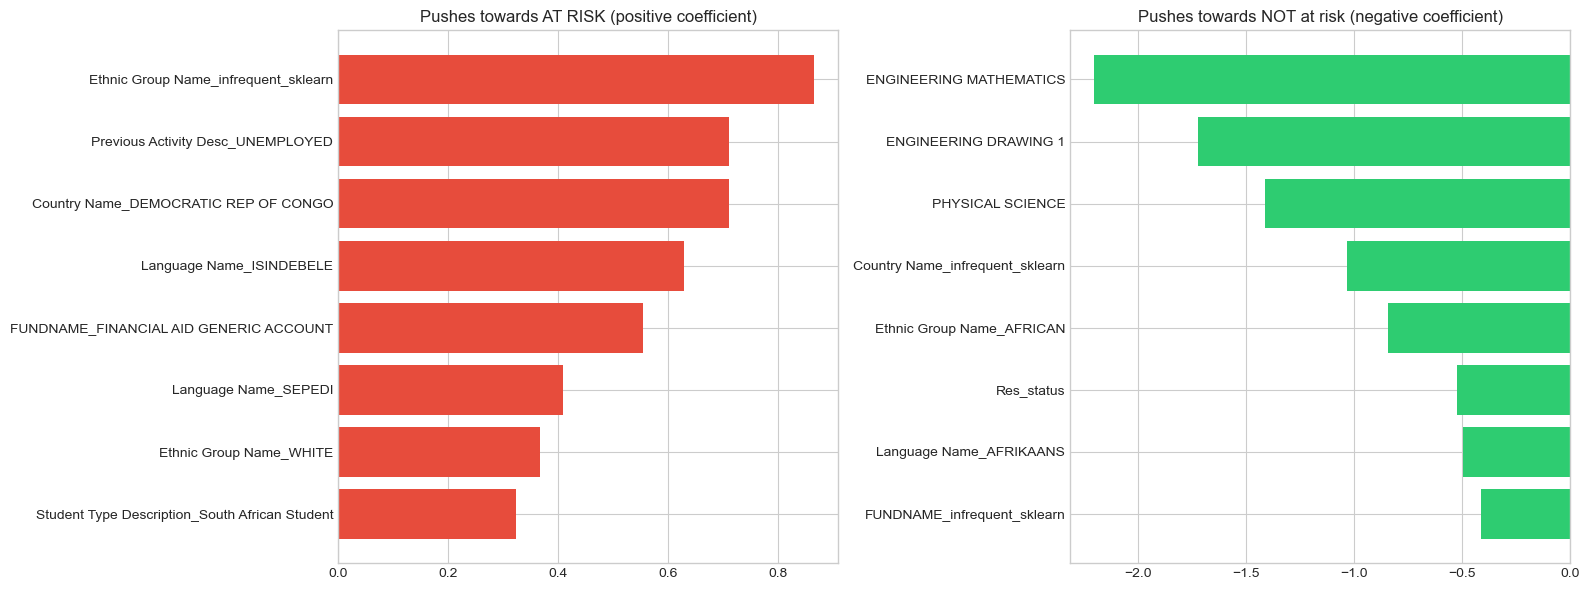

In [ ]:
# Linear-kernel SVM coefficients 
lin = Pipeline([("preprocess", make_preprocessor(ALL_FEATURES, scale=True)),
                ("classifier", SVC(kernel="linear", C=1.0, class_weight="balanced", random_state=RANDOM_STATE))]).fit(X_train, y_train)
names = lin.named_steps["preprocess"].get_feature_names_out()
coef = pd.DataFrame({"Encoded feature": names, "Coefficient": lin.named_steps["classifier"].coef_[0]})
coef["Abs"] = coef["Coefficient"].abs()
coef = coef.sort_values("Abs", ascending=False).drop(columns="Abs").reset_index(drop=True)
save_table("T_linear_svm_coefficients", coef.round(4).head(20))

pos = coef[coef["Coefficient"] > 0].head(8).iloc[::-1]; neg = coef[coef["Coefficient"] < 0].head(8).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].barh(pos["Encoded feature"].str.split("__").str[1], pos["Coefficient"], color="#e74c3c"); axes[0].set_title("Pushes towards AT RISK (positive coefficient)")
axes[1].barh(neg["Encoded feature"].str.split("__").str[1], neg["Coefficient"], color="#2ecc71"); axes[1].set_title("Pushes towards NOT at risk (negative coefficient)")
plt.tight_layout(); finish_fig("F_linear_svm_coefficients")

## 9. SHAP


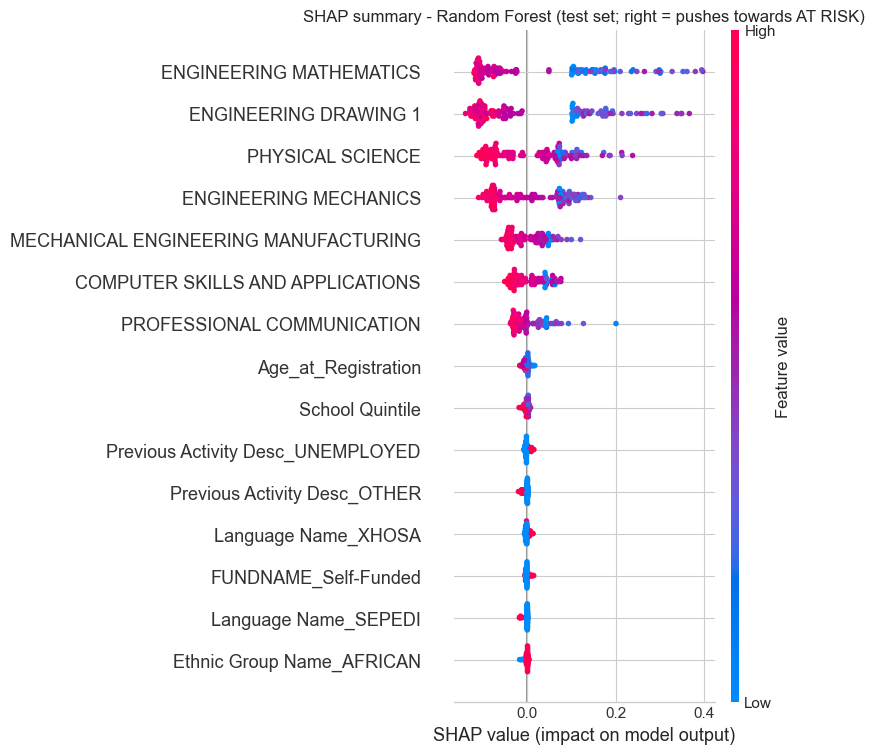

,Feature,Mean |SHAP|
0,ENGINEERING MATHEMATICS,0.1282
1,ENGINEERING DRAWING 1,0.1217
2,PHYSICAL SCIENCE,0.0785
3,ENGINEERING MECHANICS,0.0742
4,MECHANICAL ENGINEERING MANUFACTURING,0.0360
5,COMPUTER SKILLS AND APPLICATIONS,0.0306
6,PROFESSIONAL COMMUNICATION,0.0262
7,Previous Activity Desc,0.0064
8,Language Name,0.0057
9,Age_at_Registration,0.0045


In [ ]:
def clean_names(names):
    return [n.split("__", 1)[1] if "__" in n else n for n in names]

def grouped_mean_abs_shap(sv, enc_names):
    groups = pd.Series([group_of(n, ALL_FEATURES) for n in enc_names])
    per_row = pd.DataFrame(sv).T.groupby(groups.values).sum().T        # sum SHAP over dummies of one variable, per student
    return per_row.abs().mean().sort_values(ascending=False).rename("Mean |SHAP|").reset_index().rename(columns={"index": "Feature"})

# Random Forest SHAP values (test set)
pre = rf_final.named_steps["preprocess"]; clf = rf_final.named_steps["classifier"]
Xte_rf = pre.transform(X_test[ALL_FEATURES]); enc_rf = pre.get_feature_names_out()
sv = shap.TreeExplainer(clf).shap_values(Xte_rf, check_additivity=False)
sv_rf = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if np.ndim(sv) == 3 else sv)

shap.summary_plot(sv_rf, Xte_rf, feature_names=clean_names(enc_rf), show=False, max_display=15)
plt.title("SHAP summary - Random Forest (test set; right = pushes towards AT RISK)")
finish_fig("F_shap_rf_summary", plt.gcf())

shap_rf_grp = grouped_mean_abs_shap(sv_rf, enc_rf)
save_table("T_shap_rf_grouped", shap_rf_grp.round(4).head(15))

c:\Users\TshushaP\AppData\Local\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\TshushaP\AppData\Local\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\TshushaP\AppData\Local\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\TshushaP\AppData\Local\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executab

KernelExplainer finished in 13s for 100 students


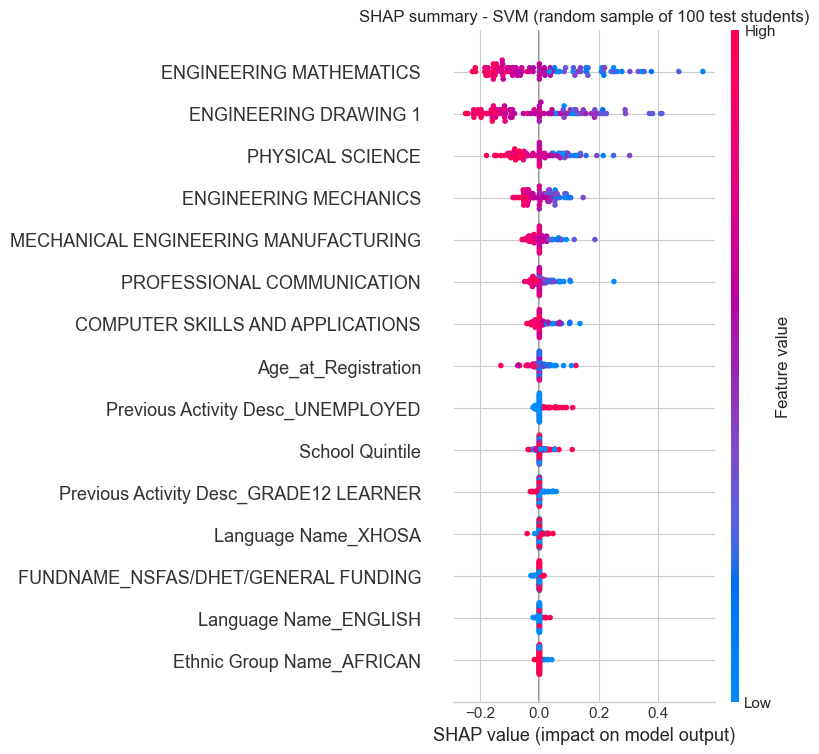

,Feature,Mean |SHAP|
0,ENGINEERING MATHEMATICS,0.1375
1,ENGINEERING DRAWING 1,0.1375
2,PHYSICAL SCIENCE,0.0712
3,ENGINEERING MECHANICS,0.0432
4,MECHANICAL ENGINEERING MANUFACTURING,0.0264
5,PROFESSIONAL COMMUNICATION,0.0231
6,Previous Activity Desc,0.0207
7,COMPUTER SKILLS AND APPLICATIONS,0.0196
8,Age_at_Registration,0.0180
9,School Quintile,0.0113


In [24]:
# ---------------- SVM ----------------
if RUN_SHAP_SVM:
    pre_s = svm_final.named_steps["preprocess"]; clf_s = svm_final.named_steps["classifier"]
    Xtr_s = pre_s.transform(X_train[ALL_FEATURES]); Xte_s = pre_s.transform(X_test[ALL_FEATURES]); enc_s = pre_s.get_feature_names_out()
    rng = np.random.default_rng(RANDOM_STATE)
    idx = rng.choice(len(Xte_s), size=min(SHAP_N, len(Xte_s)), replace=False)
    background = shap.kmeans(Xtr_s, 20)
    t0 = time.time()
    expl = shap.KernelExplainer(lambda a: clf_s.predict_proba(a)[:, 1], background)
    sv_svm = np.asarray(expl.shap_values(Xte_s[idx], nsamples=300, silent=True))
    print(f"KernelExplainer finished in {time.time()-t0:.0f}s for {len(idx)} students")

    shap.summary_plot(sv_svm, Xte_s[idx], feature_names=clean_names(enc_s), show=False, max_display=15)
    plt.title(f"SHAP summary - SVM (random sample of {len(idx)} test students)")
    finish_fig("F_shap_svm_summary", plt.gcf())
    shap_svm_grp = grouped_mean_abs_shap(sv_svm, enc_s)
    save_table("T_shap_svm_grouped", shap_svm_grp.round(4).head(15))
else:
    print("SVM SHAP skipped (RUN_SHAP_SVM = False).")

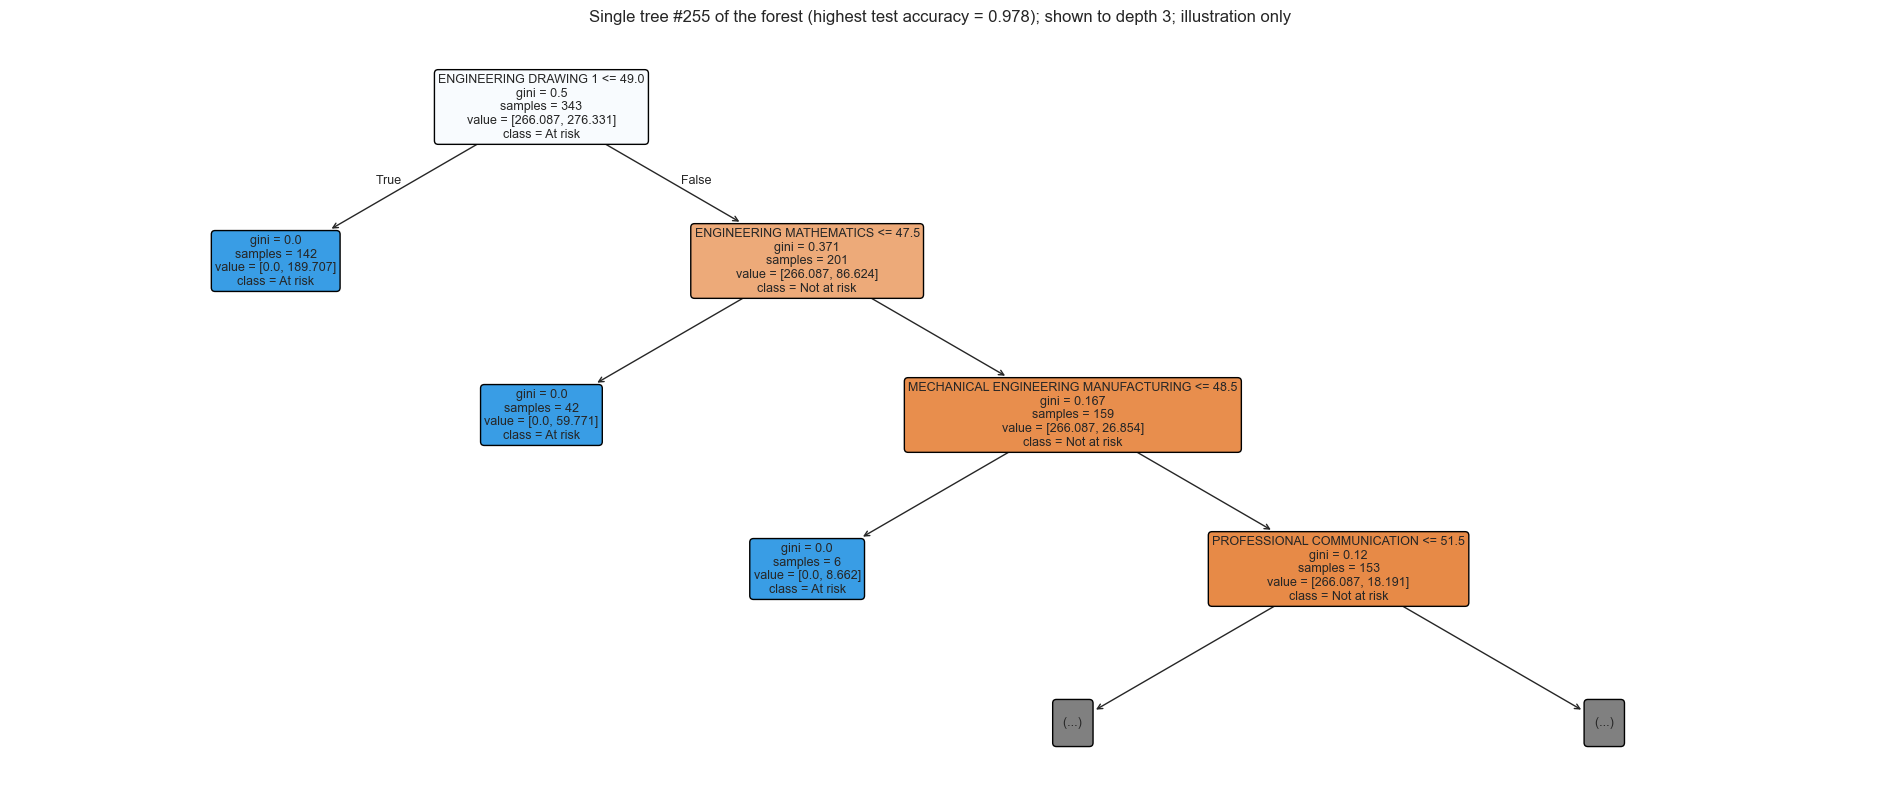

In [ ]:
pre = rf_final.named_steps["preprocess"]; est = rf_final.named_steps["classifier"].estimators_
acc = [accuracy_score(y_test, t.predict(Xte_rf)) for t in est]
best_tree = int(np.argmax(acc))
plt.figure(figsize=(24, 10))
plot_tree(est[best_tree], feature_names=clean_names(enc_rf), class_names=["Not at risk", "At risk"],
          filled=True, rounded=True, max_depth=3, fontsize=9)
plt.title(f"Single tree #{best_tree} of the forest (highest test accuracy = {acc[best_tree]:.3f}); shown to depth 3; illustration only")
finish_fig("F_rf_example_tree")

## 10. Robustness


In [26]:
rows = []
for name in (svm_name, rf_name, "SVM (background only)", "Random Forest (background only)"):
    feats = FEATS_OF[name]
    cv = cross_validate(clone(CANDIDATES[name]), X_all[feats], y_all, cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE),
                        scoring=SCORING, n_jobs=-1)
    r = {"Model": name, "Folds x repeats": "5 x 5"}
    for k in SCORING:
        r[f"{k} mean"] = cv[f"test_{k}"].mean(); r[f"{k} SD"] = cv[f"test_{k}"].std()
    rows.append(r)
rep_cv = pd.DataFrame(rows).round(4)
save_table("T_repeated_cv_all_students", rep_cv)

,Model,Folds x repeats,accuracy mean,accuracy SD,precision mean,precision SD,recall mean,recall SD,f1 mean,f1 SD,roc_auc mean,roc_auc SD
0,SVM (tuned),5 x 5,0.9335,0.0187,0.9629,0.0168,0.9203,0.0285,0.9408,0.0174,0.9842,0.0066
1,Random Forest (tuned),5 x 5,0.9735,0.0138,0.9734,0.0158,0.9811,0.0150,0.9771,0.0120,0.9972,0.0019
2,SVM (background only),5 x 5,0.5885,0.0419,0.6353,0.0353,0.6729,0.0589,0.6526,0.0407,0.6134,0.0450
3,Random Forest (background only),5 x 5,0.5997,0.0334,0.6399,0.0287,0.7016,0.0492,0.6685,0.0309,0.6034,0.0450


In [27]:
# Temporal validation: train on all cohorts before the last one, test on the last cohort.
last = int(cohort.max())
tr_mask = (cohort < last).values; te_mask = (cohort == last).values
print(f"Train cohorts {sorted(cohort[tr_mask].unique().tolist())} (n={tr_mask.sum()}) -> test cohort {last} (n={te_mask.sum()})")
rows = []
for name in (svm_name, rf_name, "SVM (background only)", "Random Forest (background only)"):
    feats = FEATS_OF[name]
    m = clone(CANDIDATES[name]).fit(X_all.loc[tr_mask, feats], y_all[tr_mask])
    yp = m.predict(X_all.loc[te_mask, feats]); ys = m.predict_proba(X_all.loc[te_mask, feats])[:, 1]
    r = metrics_from(y_all[te_mask], yp, ys); r["Model"] = name; rows.append(r)
temporal = pd.DataFrame(rows).set_index("Model").round(4)
temporal.insert(0, "Test cohort", last)
save_table("T_temporal_validation", temporal.reset_index())

Train cohorts [2022, 2023, 2024] (n=415) -> test cohort 2025 (n=265)


,Model,Test cohort,Accuracy,Precision,Recall,F1,Specificity,ROC-AUC,TN,FP,FN,TP
0,SVM (tuned),2025,0.9170,0.9521,0.9026,0.9267,0.9369,0.9826,104,7,15,139
1,Random Forest (tuned),2025,0.9509,0.9273,0.9935,0.9592,0.8919,0.9881,99,12,1,153
2,SVM (background only),2025,0.5774,0.6167,0.7208,0.6647,0.3784,0.5854,42,69,43,111
3,Random Forest (background only),2025,0.5623,0.6000,0.7403,0.6628,0.3153,0.5722,35,76,40,114


,Year,Model,N,At-risk %,Folds,Accuracy,Precision,Recall,F1,ROC-AUC
0,2022,SVM,119,58.8,5,0.9409,0.9438,0.9571,0.9502,0.9781
1,2023,SVM,135,54.1,5,0.8741,0.8921,0.8790,0.8821,0.9634
2,2024,SVM,161,59.0,5,0.9443,0.9684,0.9368,0.9516,0.9913
3,2025,SVM,265,58.1,5,0.9170,0.9652,0.8892,0.9254,0.9810
4,2022,Random Forest,119,58.8,5,0.9493,0.9457,0.9714,0.9576,0.9868
5,2023,Random Forest,135,54.1,5,0.9185,0.9305,0.9200,0.9236,0.9778
6,2024,Random Forest,161,59.0,5,0.9504,0.9504,0.9684,0.9587,0.9914
7,2025,Random Forest,265,58.1,5,0.9811,0.9810,0.9871,0.9838,0.9982


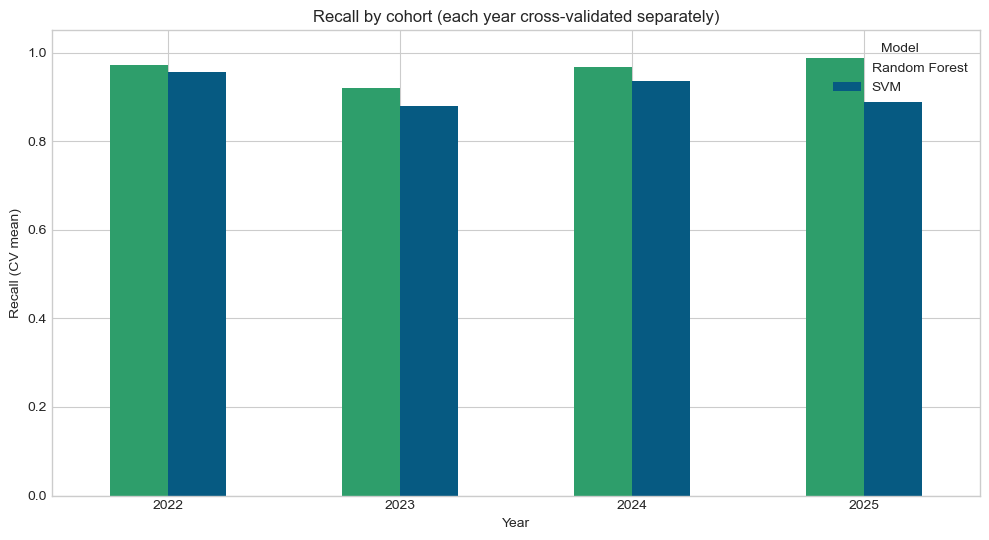

Each cohort has only ~120-270 students, so differences between years of a few points are within noise; do not attribute them to specific causes without a significance test.


In [28]:
def evaluate_by_year(model, name, feats):
    rows = []
    for yr_ in sorted(cohort.unique()):
        m = (cohort == yr_).values
        Xy, yy = X_all.loc[m, feats], y_all[m]
        folds = int(min(CV_FOLDS, yy.value_counts().min()))
        if folds < 2:
            continue
        cv = StratifiedKFold(n_splits=folds, shuffle=True, random_state=RANDOM_STATE)
        sc = cross_validate(clone(model), Xy, yy, cv=cv, scoring=SCORING, n_jobs=-1)
        rows.append({"Year": int(yr_), "Model": name, "N": len(yy), "At-risk %": round(100 * yy.mean(), 1), "Folds": folds,
                     **{k.title() if k != "roc_auc" else "ROC-AUC": sc[f"test_{k}"].mean() for k in SCORING}})
    return pd.DataFrame(rows)

by_year = pd.concat([evaluate_by_year(CANDIDATES[svm_name], "SVM", ALL_FEATURES),
                     evaluate_by_year(CANDIDATES[rf_name], "Random Forest", ALL_FEATURES)], ignore_index=True).round(4)
save_table("T_per_year_cv", by_year)

piv = by_year.pivot(index="Year", columns="Model", values="Recall")
ax = piv.plot(kind="bar", figsize=(10, 5.5), rot=0, color=["#2E9E6B", "#065A82"])
ax.set_ylim(0, 1.05); ax.set_ylabel("Recall (CV mean)"); ax.set_title("Recall by cohort (each year cross-validated separately)")
plt.tight_layout(); finish_fig("F_recall_by_year")
print("Each cohort has only ~120-270 students, so differences between years of a few points are within noise; "
      "do not attribute them to specific causes without a significance test.")

In [29]:
# Subgroup audit using out-of-fold predictions for ALL students (test-set subgroups are far too small).
def oof_pred(name):
    return cross_val_predict(clone(CANDIDATES[name]), X_all[FEATS_OF[name]], y_all, cv=CV_STRAT, n_jobs=-1)

def subgroup_table(y_true, y_pred, groups, label):
    rows = []
    for g, idx in groups.groupby(groups).groups.items():
        yt, yp = y_true.loc[idx].values, pd.Series(y_pred, index=y_true.index).loc[idx].values
        tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
        rows.append({"Variable": label, "Group": g, "n": len(idx), "At-risk %": round(yt.mean() * 100, 1),
                     "Recall": tp / (tp + fn) if tp + fn else np.nan, "False-positive rate": fp / (fp + tn) if fp + tn else np.nan,
                     "Precision": tp / (tp + fp) if tp + fp else np.nan, "Small group (n<30)": "yes" if len(idx) < 30 else ""})
    return pd.DataFrame(rows)

audit_vars = ["Gender", "Ethnic Group Name", "Funded", "Res_status", "School Quintile"]
audit = []
for model_name in (rf_name if PRIMARY == rf_name else svm_name, "Random Forest (background only)"):
    yp = oof_pred(model_name)
    for v in audit_vars:
        t = subgroup_table(y_all, yp, df_cc[v].fillna("Missing").astype(str), v); t.insert(0, "Model", model_name); audit.append(t)
audit_df = pd.concat(audit, ignore_index=True).round(3)
save_table("T_subgroup_audit", audit_df)
print("Look for groups whose recall or false-positive rate differs a lot from the overall rate (ignore groups flagged n<30).")

,Model,Variable,Group,n,At-risk %,Recall,False-positive rate,Precision,Small group (n<30)
0,Random Forest (tuned),Gender,F,189,58.7,0.973,0.026,0.982,
1,Random Forest (tuned),Gender,M,491,57.2,0.982,0.038,0.972,
2,Random Forest (tuned),Ethnic Group Name,AFRICAN,587,60.3,0.980,0.039,0.975,
3,Random Forest (tuned),Ethnic Group Name,COLOURED,64,40.6,1.000,0.026,0.963,
4,Random Forest (tuned),Ethnic Group Name,INDIAN,2,50.0,1.000,0.000,1.000,yes
5,Random Forest (tuned),Ethnic Group Name,OTHER,3,66.7,1.000,0.000,1.000,yes
6,Random Forest (tuned),Ethnic Group Name,WHITE,24,37.5,0.889,0.000,1.000,yes
7,Random Forest (tuned),Funded,No,138,49.3,0.956,0.029,0.970,
8,Random Forest (tuned),Funded,Yes,542,59.8,0.985,0.037,0.976,
9,Random Forest (tuned),Res_status,No,426,57.0,0.979,0.038,0.971,


Look for groups whose recall or false-positive rate differs a lot from the overall rate (ignore groups flagged n<30).


## 11. Module-level analysis (same 680 students as the models)


,Module,N,N failed,Failure rate (%),95% CI,Pass rate (%)
0,Eng Maths,680,257,37.8,34.2-41.5,62.2
1,Eng Drawing,680,256,37.6,34.1-41.3,62.4
2,Eng Mechanics,680,209,30.7,27.4-34.3,69.3
3,Phys Science,680,145,21.3,18.4-24.6,78.7
4,Mech Manuf,680,110,16.2,13.6-19.1,83.8
5,Prof Comm,680,80,11.8,9.6-14.4,88.2
6,Comp Skills,680,76,11.2,9.0-13.8,88.8


,Module,N (available marks),"Failure rate (%), all students","Failure rate (%), complete cases",Difference (pp)
0,Comp Skills,720,12.5,11.2,1.3
1,Eng Drawing,685,37.8,37.6,0.2
2,Eng Maths,715,37.3,37.8,-0.5
3,Eng Mechanics,718,31.3,30.7,0.6
4,Mech Manuf,712,17.3,16.2,1.1
5,Phys Science,717,22.7,21.3,1.4
6,Prof Comm,720,13.6,11.8,1.8


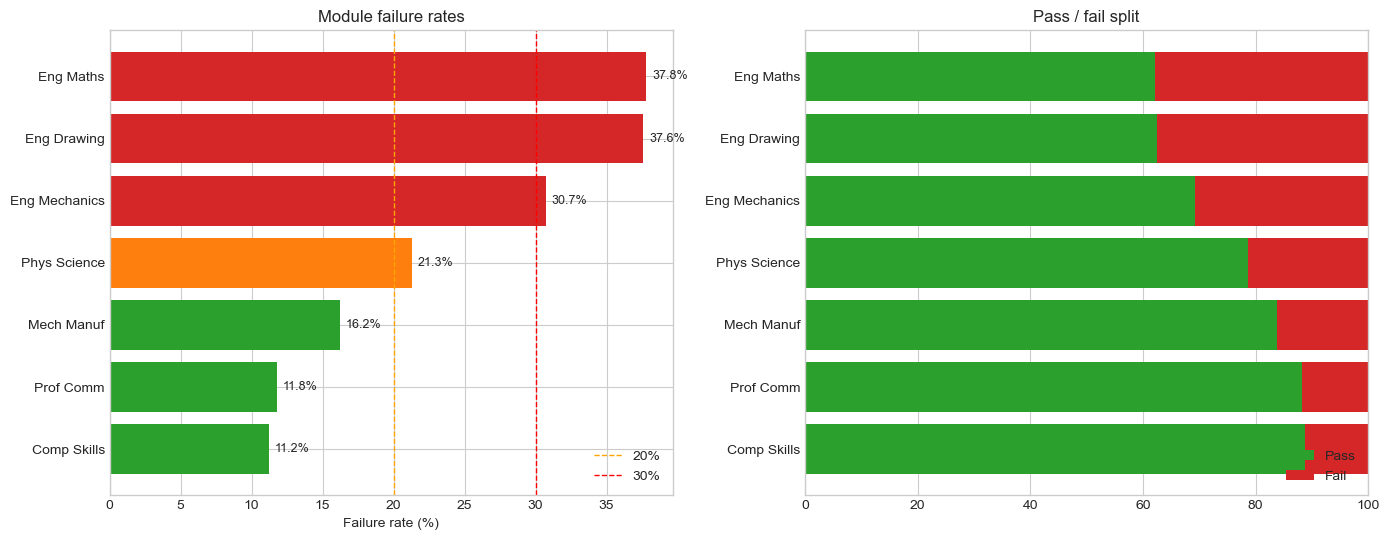

The 20% and 30% thresholds are descriptive cut-offs chosen for presentation; justify them in the Methods chapter.


In [30]:
marks = df_cc[MODULES]
fail = (marks < PASS_MARK)                      # boolean, no NaNs after the complete-case filter
assert marks.notna().all().all()

# --- overall failure rates with Wilson CIs ---
rows = []
for m in MODULES:
    n, k = len(marks), int(fail[m].sum())
    lo, hi = wilson(k, n)
    rows.append({"Module": SHORT[m], "N": n, "N failed": k, "Failure rate (%)": round(k / n * 100, 1),
                 "95% CI": f"{lo:.1f}-{hi:.1f}", "Pass rate (%)": round((n - k) / n * 100, 1)})
overall = pd.DataFrame(rows).sort_values("Failure rate (%)", ascending=False).reset_index(drop=True)
save_table("T_module_failure_rates", overall)

# --- sensitivity: what if students with some missing marks are kept (rates use available marks only)? ---
rows = []
for m in MODULES:
    v = df_raw[m].dropna(); rows.append({"Module": SHORT[m], "N (available marks)": len(v),
                                         "Failure rate (%), all students": round((v < PASS_MARK).mean() * 100, 1),
                                         "Failure rate (%), complete cases": overall.set_index("Module").loc[SHORT[m], "Failure rate (%)"]})
sens = pd.DataFrame(rows)
sens["Difference (pp)"] = (sens["Failure rate (%), all students"] - sens["Failure rate (%), complete cases"]).round(1)
save_table("T_failure_rates_sensitivity", sens)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
colors = ["#d62728" if r >= 30 else "#ff7f0e" if r >= 20 else "#2ca02c" for r in overall["Failure rate (%)"]]
axes[0].barh(overall["Module"], overall["Failure rate (%)"], color=colors)
axes[0].axvline(20, color="orange", ls="--", lw=1, label="20%"); axes[0].axvline(30, color="red", ls="--", lw=1, label="30%")
for i, r in overall.iterrows():
    axes[0].text(r["Failure rate (%)"] + 0.4, i, f'{r["Failure rate (%)"]}%', va="center", fontsize=9)
axes[0].invert_yaxis(); axes[0].set_xlabel("Failure rate (%)"); axes[0].set_title("Module failure rates"); axes[0].legend()
axes[1].barh(overall["Module"], overall["Pass rate (%)"], color="#2ca02c", label="Pass")
axes[1].barh(overall["Module"], overall["Failure rate (%)"], left=overall["Pass rate (%)"], color="#d62728", label="Fail")
axes[1].invert_yaxis(); axes[1].set_xlim(0, 100); axes[1].set_title("Pass / fail split"); axes[1].legend(loc="lower right")
plt.tight_layout(); finish_fig("F_module_failure_rates")
print("The 20% and 30% thresholds are descriptive cut-offs chosen for presentation; justify them in the Methods chapter.")

Academic Year,index,2022,2023,2024,2025
0,Eng Maths,31.9,28.9,32.9,47.9
1,Eng Drawing,36.1,40.7,36.6,37.4
2,Eng Mechanics,35.3,32.6,24.8,31.3
3,Phys Science,41.2,10.4,16.8,20.8
4,Mech Manuf,12.6,9.6,28.0,14.0
5,Prof Comm,10.9,20.7,3.7,12.5
6,Comp Skills,9.2,11.1,6.2,15.1


,Module,Rate first year (%),Rate last year (%),Odds ratio per year,"p (linear trend, logit)",p (any difference between years),"p (trend, Holm)",Direction
0,Comp Skills,9.2,15.1,1.2025,0.1042,0.0360,0.5210,no clear trend
1,Eng Drawing,36.1,37.4,0.9934,0.9247,0.8627,1.0000,no clear trend
2,Eng Maths,31.9,47.9,1.3091,0.0002,0.0002,0.0016,WORSENING
3,Eng Mechanics,35.3,31.3,0.9378,0.3828,0.2564,1.0000,no clear trend
4,Mech Manuf,12.6,14.0,1.1055,0.2884,0.0000,1.0000,no clear trend
5,Phys Science,41.2,20.8,0.7936,0.0049,0.0000,0.0294,IMPROVING
6,Prof Comm,10.9,12.5,0.9124,0.3802,0.0001,1.0000,no clear trend


With only four cohorts, a trend is a weak statement; Holm-adjusted p-values guard against over-reading seven tests.


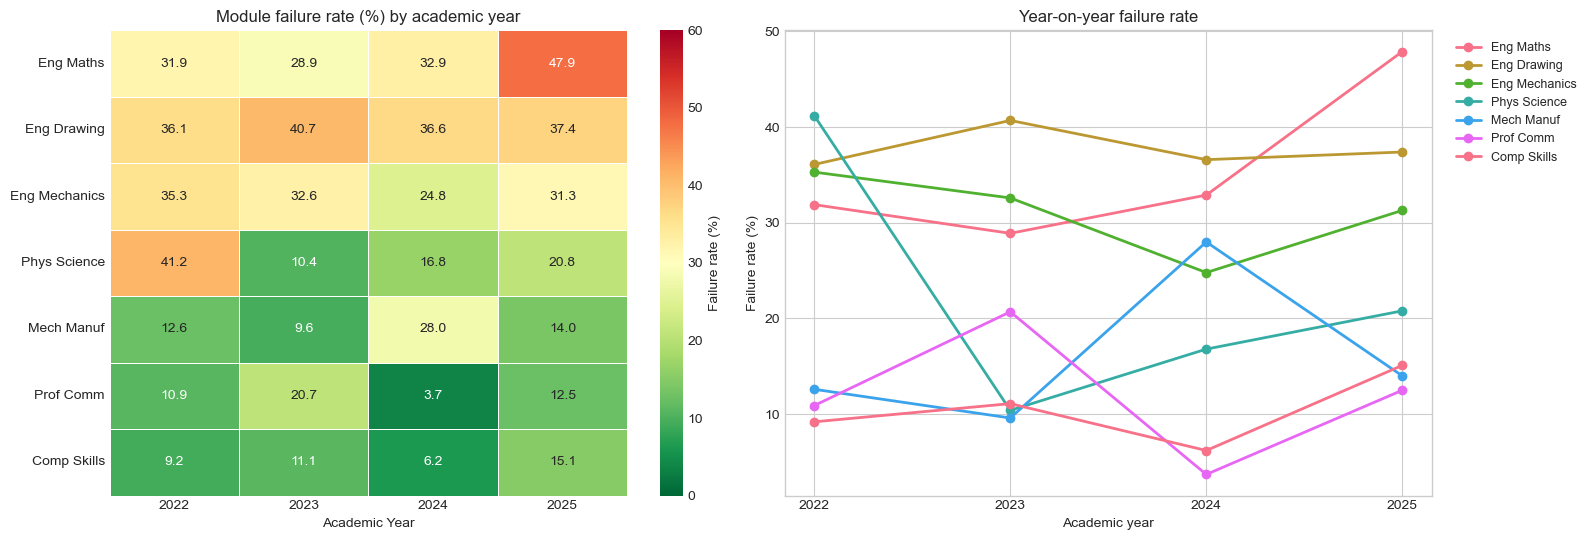

In [31]:
# --- yearly failure rates + proper trend tests ---
years = sorted(cohort.unique())
yr_rate = pd.DataFrame({SHORT[m]: [fail.loc[cohort == y_, m].mean() * 100 for y_ in years] for m in MODULES}, index=years).T
yr_rate.columns.name = "Academic Year"
yr_rate = yr_rate.loc[overall["Module"]].round(1)
save_table("T_module_failure_by_year", yr_rate.reset_index())

trend_rows = []
for m in MODULES:
    f = fail[m].astype(int).values; t = (cohort.values - cohort.min()).astype(float)
    logit = sm.Logit(f, sm.add_constant(t)).fit(disp=0)
    chi, p_chi, *_ = stats.chi2_contingency(pd.crosstab(cohort, fail[m]))
    trend_rows.append({"Module": SHORT[m], "Rate first year (%)": round(yr_rate.loc[SHORT[m], years[0]], 1),
                       "Rate last year (%)": round(yr_rate.loc[SHORT[m], years[-1]], 1),
                       "Odds ratio per year": np.exp(logit.params[1]), "p (linear trend, logit)": logit.pvalues[1],
                       "p (any difference between years)": p_chi})
trend = pd.DataFrame(trend_rows)
trend["p (trend, Holm)"] = multipletests(trend["p (linear trend, logit)"], method="holm")[1]
trend["Direction"] = np.where(trend["p (trend, Holm)"] < 0.05, np.where(trend["Odds ratio per year"] > 1, "WORSENING", "IMPROVING"), "no clear trend")
save_table("T_module_trend_tests", trend.round(4))
print("With only four cohorts, a trend is a weak statement; Holm-adjusted p-values guard against over-reading seven tests.")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.heatmap(yr_rate, annot=True, fmt=".1f", cmap="RdYlGn_r", vmin=0, vmax=60, linewidths=0.5, ax=axes[0], cbar_kws={"label": "Failure rate (%)"})
axes[0].set_title("Module failure rate (%) by academic year"); axes[0].set_ylabel("")
for m in yr_rate.index:
    axes[1].plot(years, yr_rate.loc[m].values, marker="o", lw=2, label=m)
axes[1].set_xticks(years); axes[1].set_xlabel("Academic year"); axes[1].set_ylabel("Failure rate (%)")
axes[1].set_title("Year-on-year failure rate"); axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.tight_layout(); finish_fig("F_module_failure_by_year")

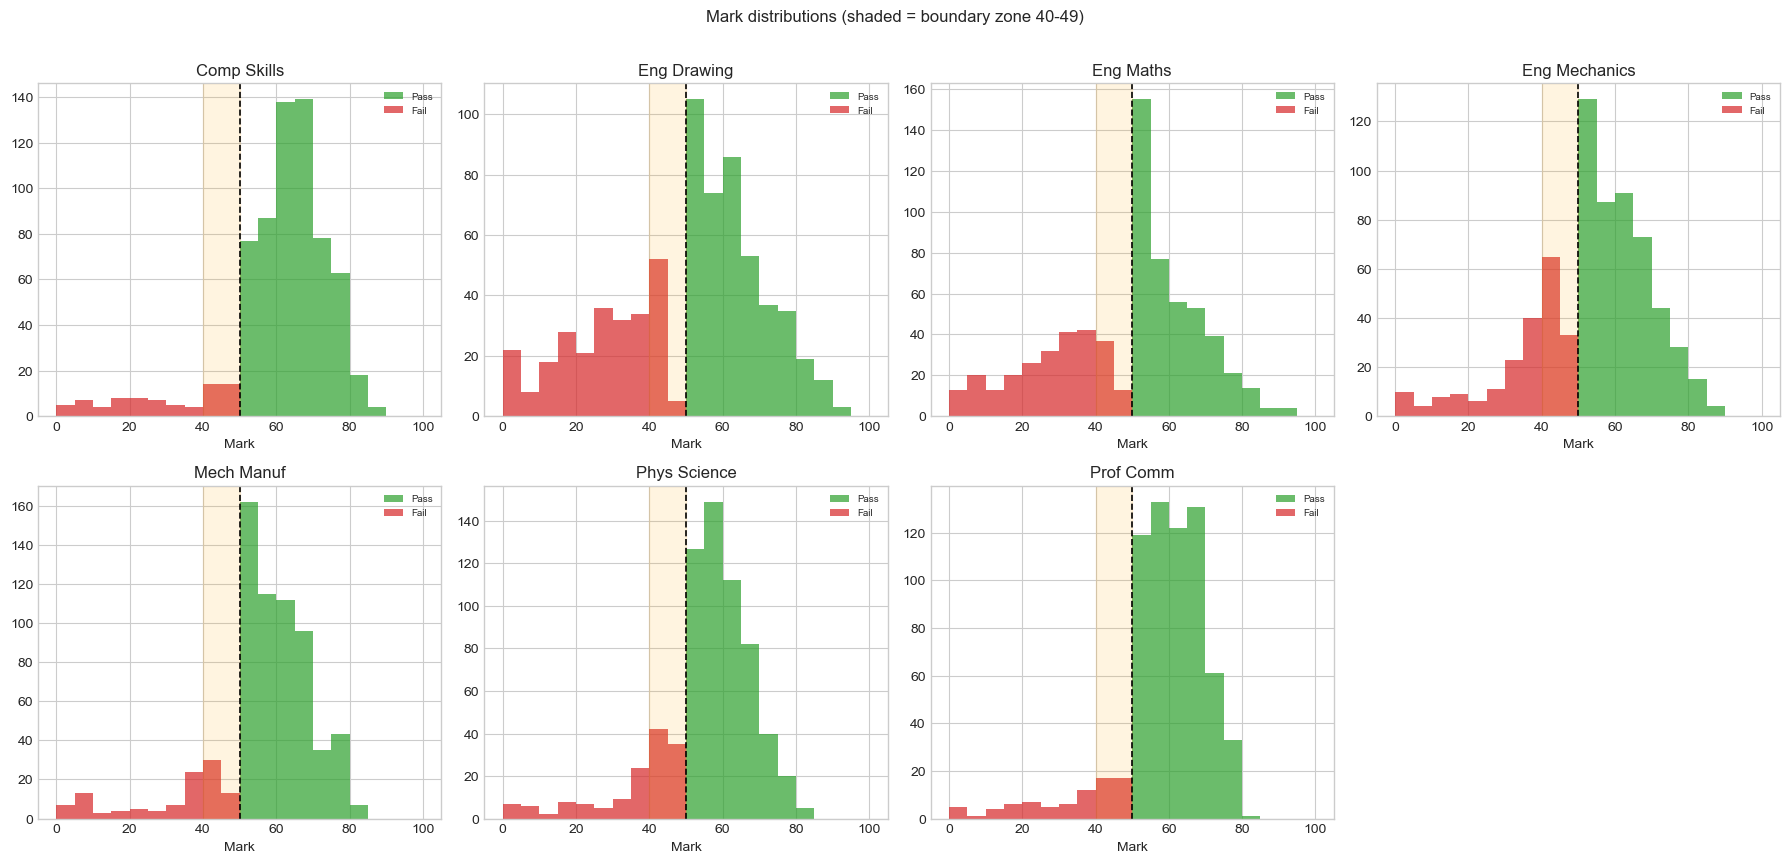

,Module,N,Deep fail (<40) n,Deep fail (<40) %,Boundary (40-49) n,Boundary (40-49) %,Mean mark,Median mark
0,Eng Mechanics,680,111,16.3,98,14.4,53.3,55.0
1,Phys Science,680,68,10.0,77,11.3,54.8,57.0
2,Eng Drawing,680,199,29.3,57,8.4,49.5,53.0
3,Eng Maths,680,207,30.4,50,7.4,48.1,51.0
4,Mech Manuf,680,67,9.9,43,6.3,55.9,57.0
5,Prof Comm,680,46,6.8,34,5.0,58.3,60.0
6,Comp Skills,680,48,7.1,28,4.1,60.6,63.0


Pass mark = 50. Check: deep fail % + boundary % equals the failure rate for every module.


,Module,"Median mark, not at risk","Median mark, at risk"
0,Comp Skills,68.0,59.0
1,Eng Drawing,63.0,39.0
2,Eng Maths,61.0,38.0
3,Eng Mechanics,65.0,47.0
4,Mech Manuf,64.0,53.0
5,Phys Science,63.0,52.0
6,Prof Comm,65.0,56.0


In [32]:
# --- mark distributions, boundary zone ---
fig, axes = plt.subplots(2, 4, figsize=(18, 8.5)); axes = axes.ravel()
for ax, m in zip(axes, MODULES):
    v = marks[m]
    ax.hist(v[v >= PASS_MARK], bins=20, range=(0, 100), color="#2ca02c", alpha=0.7, label="Pass")
    ax.hist(v[v < PASS_MARK], bins=20, range=(0, 100), color="#d62728", alpha=0.7, label="Fail")
    ax.axvline(PASS_MARK, color="k", ls="--", lw=1.2); ax.axvspan(BOUNDARY_LOW, PASS_MARK, alpha=0.12, color="orange")
    ax.set_title(SHORT[m]); ax.set_xlabel("Mark"); ax.legend(fontsize=7)
axes[-1].axis("off")
plt.suptitle("Mark distributions (shaded = boundary zone 40-49)", y=1.01); plt.tight_layout(); finish_fig("F_mark_distributions")

rows = []
for m in MODULES:
    v = marks[m]; n = len(v)
    deep, bnd = int((v < BOUNDARY_LOW).sum()), int(((v >= BOUNDARY_LOW) & (v < PASS_MARK)).sum())
    rows.append({"Module": SHORT[m], "N": n, "Deep fail (<40) n": deep, "Deep fail (<40) %": round(deep / n * 100, 1),
                 "Boundary (40-49) n": bnd, "Boundary (40-49) %": round(bnd / n * 100, 1),
                 "Mean mark": round(v.mean(), 1), "Median mark": round(v.median(), 1)})
boundary = pd.DataFrame(rows).sort_values("Boundary (40-49) %", ascending=False).reset_index(drop=True)
save_table("T_boundary_zone", boundary)
print(f"Pass mark = {PASS_MARK}. Check: deep fail % + boundary % equals the failure rate for every module.")
chk = boundary.set_index("Module")[["Deep fail (<40) %", "Boundary (40-49) %"]].sum(axis=1).round(1)
assert (chk - overall.set_index("Module")["Failure rate (%)"].reindex(chk.index)).abs().max() < 0.2

# at-risk vs not-at-risk marks. These groups differ BY CONSTRUCTION; report medians, not 'significance'.
med = pd.DataFrame({SHORT[m]: [marks.loc[df_cc["At_Risk"] == g, m].median() for g in (0, 1)] for m in MODULES},
                   index=["Median mark, not at risk", "Median mark, at risk"]).T.round(1)
save_table("T_median_marks_by_risk", med.reset_index().rename(columns={"index": "Module"}))

,Module A,Module B,Both failed,Failed either,Jaccard (%)
0,Eng Drawing,Eng Mechanics,162,303,53.5
1,Eng Maths,Eng Mechanics,162,304,53.3
2,Eng Mechanics,Phys Science,119,235,50.6
3,Eng Drawing,Eng Maths,157,356,44.1
4,Eng Maths,Phys Science,117,285,41.1
5,Mech Manuf,Phys Science,74,181,40.9
6,Comp Skills,Prof Comm,45,111,40.5
7,Comp Skills,Mech Manuf,51,135,37.8
8,Eng Mechanics,Mech Manuf,87,232,37.5
9,Mech Manuf,Prof Comm,49,141,34.8


Jaccard = (students failing BOTH) / (students failing EITHER). Define this in the Methods chapter.


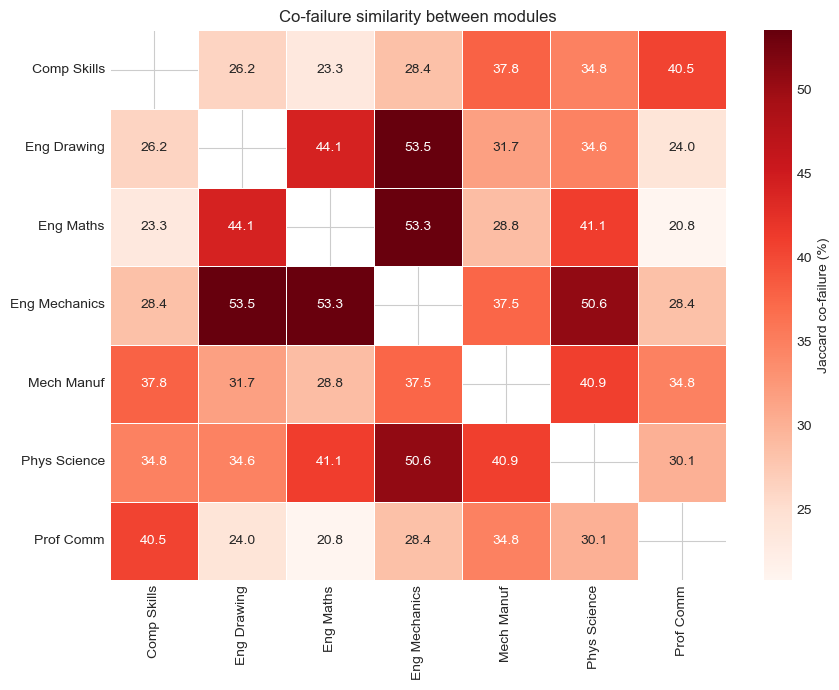

,Modules failed (>=),Students,%
0,0,680,100.0
1,1,392,57.6
2,2,269,39.6
3,3,184,27.1
4,4,126,18.5
5,5,74,10.9
6,6,52,7.6
7,7,36,5.3


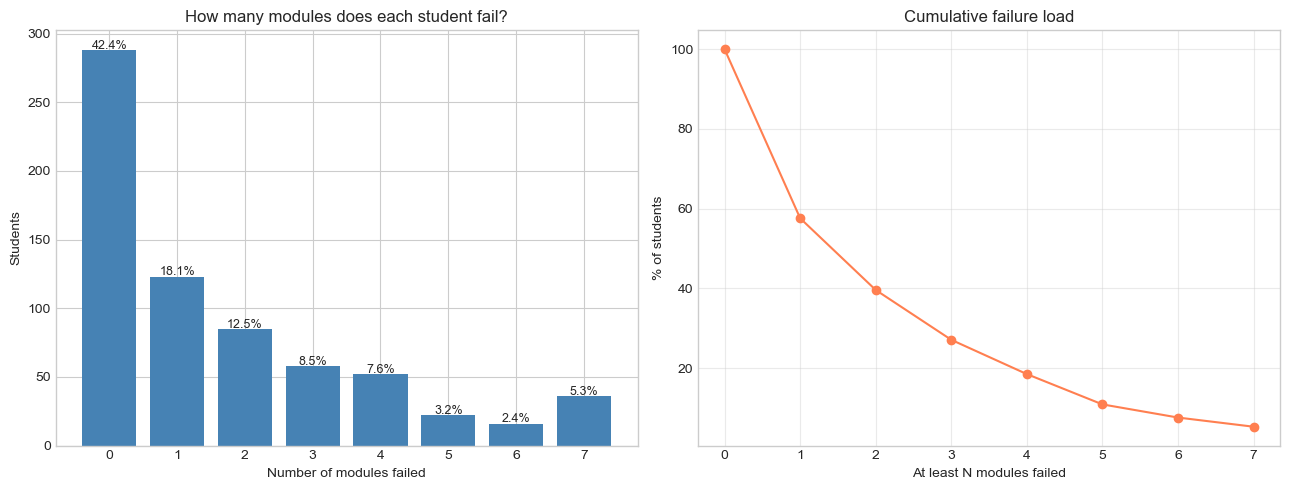

In [33]:
# --- co-failure (Jaccard), failure load, bottleneck score ---
def jaccard_table():
    rows = []
    for a, b in combinations(MODULES, 2):
        both = int((fail[a] & fail[b]).sum()); union = int((fail[a] | fail[b]).sum())
        rows.append({"Module A": SHORT[a], "Module B": SHORT[b], "Both failed": both, "Failed either": union,
                     "Jaccard (%)": round(both / union * 100, 1) if union else 0})
    return pd.DataFrame(rows).sort_values("Jaccard (%)", ascending=False).reset_index(drop=True)
co_df = jaccard_table()
save_table("T_cofailure_jaccard", co_df)
print("Jaccard = (students failing BOTH) / (students failing EITHER). Define this in the Methods chapter.")

pivot = pd.DataFrame(index=[SHORT[m] for m in MODULES], columns=[SHORT[m] for m in MODULES], dtype=float)
for m in MODULES:
    pivot.loc[SHORT[m], SHORT[m]] = fail[m].mean() * 100
for _, r in co_df.iterrows():
    pivot.loc[r["Module A"], r["Module B"]] = pivot.loc[r["Module B"], r["Module A"]] = r["Jaccard (%)"]
plt.figure(figsize=(9, 7))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds", mask=np.eye(len(MODULES), dtype=bool), linewidths=0.5,
            cbar_kws={"label": "Jaccard co-failure (%)"})
plt.title("Co-failure similarity between modules"); plt.tight_layout(); finish_fig("F_cofailure_heatmap")

# failure load
load = fail.sum(axis=1)
vc = load.value_counts().sort_index()
load_tbl = pd.DataFrame({"Modules failed (>=)": range(0, 8)})
load_tbl["Students"] = [(load >= k).sum() for k in load_tbl["Modules failed (>=)"]]
load_tbl["%"] = (load_tbl["Students"] / len(load) * 100).round(1)
save_table("T_failure_load", load_tbl)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(vc.index, vc.values, color="steelblue")
for xi, yi in zip(vc.index, vc.values):
    axes[0].text(xi, yi + 1, f"{yi/len(load)*100:.1f}%", ha="center", fontsize=9)
axes[0].set_xlabel("Number of modules failed"); axes[0].set_ylabel("Students"); axes[0].set_title("How many modules does each student fail?")
axes[1].plot(load_tbl["Modules failed (>=)"], load_tbl["%"], marker="o", color="coral"); axes[1].set_xlabel("At least N modules failed")
axes[1].set_ylabel("% of students"); axes[1].set_title("Cumulative failure load"); axes[1].grid(alpha=0.4)
plt.tight_layout(); finish_fig("F_failure_load")

,Module,N failed,Prevalence (%),Avg other modules failed,Sole failure (%),Bottleneck score
0,Eng Mechanics,209,30.7,3.14,2.9,96.62
1,Eng Drawing,256,37.6,2.52,17.2,94.71
2,Eng Maths,257,37.8,2.49,20.6,93.97
3,Phys Science,145,21.3,3.60,6.9,76.76
4,Mech Manuf,110,16.2,3.92,3.6,63.38
5,Comp Skills,76,11.2,4.58,1.3,51.18
6,Prof Comm,80,11.8,4.16,6.2,48.97


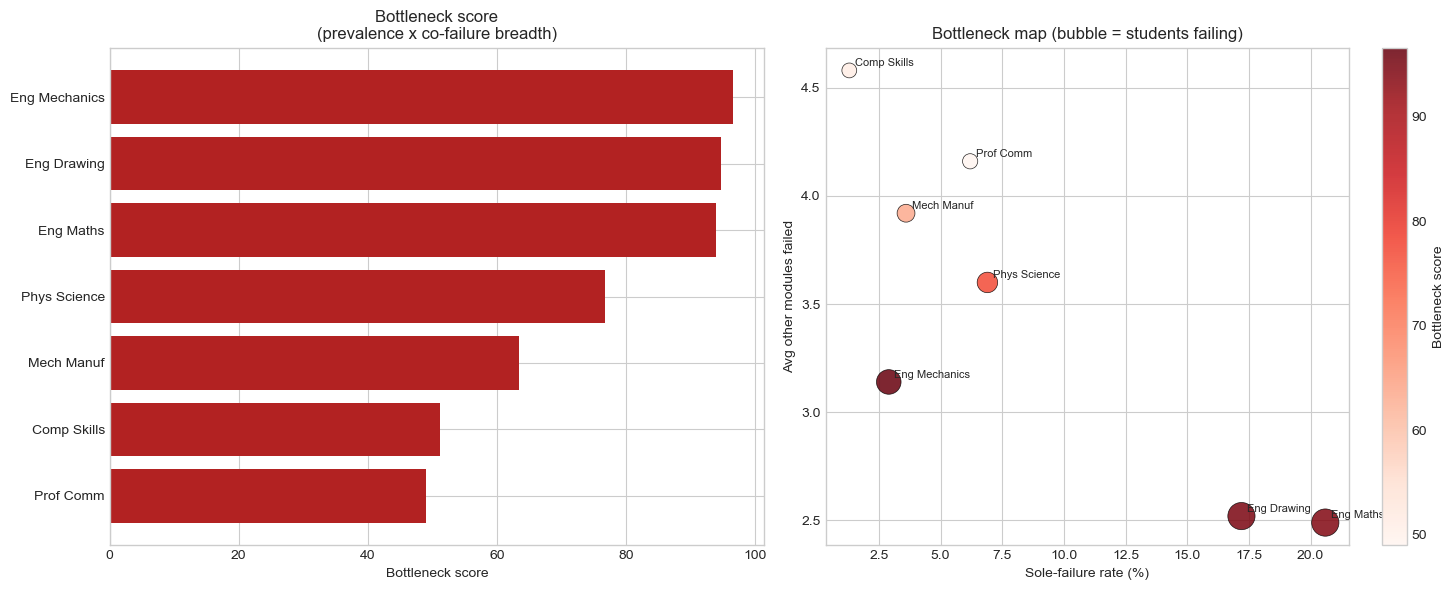

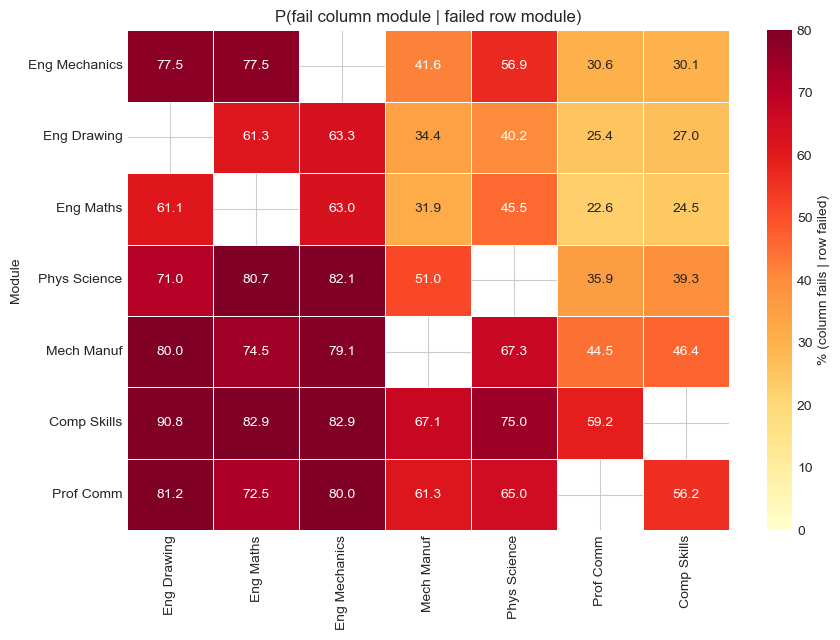

,Module,N,N failed,Failure rate (%),Pass rate (%),Lowest yearly rate,Highest yearly rate,Boundary (40-49) %,Deep fail (<40) %,Bottleneck score
0,Eng Maths,680,257,37.8,62.2,28.9,47.9,7.4,30.4,93.97
1,Eng Drawing,680,256,37.6,62.4,36.1,40.7,8.4,29.3,94.71
2,Eng Mechanics,680,209,30.7,69.3,24.8,35.3,14.4,16.3,96.62
3,Phys Science,680,145,21.3,78.7,10.4,41.2,11.3,10.0,76.76
4,Mech Manuf,680,110,16.2,83.8,9.6,28.0,6.3,9.9,63.38
5,Prof Comm,680,80,11.8,88.2,3.7,20.7,5.0,6.8,48.97
6,Comp Skills,680,76,11.2,88.8,6.2,15.1,4.1,7.1,51.18


In [ ]:
# --- Bottleneck score ---

rows = []
for m in MODULES:
    f_m = fail[fail[m]]
    others = [c for c in MODULES if c != m]
    n_m = len(f_m); n_other = f_m[others].sum(axis=1)
    cond = {f"P(fail {SHORT[o]} | fail this)": round(float((fail[m] & fail[o]).sum() / n_m * 100), 1) for o in others}
    rows.append({"Module": SHORT[m], "N failed": n_m, "Prevalence (%)": round(n_m / len(fail) * 100, 1),
                 "Avg other modules failed": round(n_other.mean(), 2), "Sole failure (%)": round((n_other == 0).mean() * 100, 1),
                 "Bottleneck score": round(n_other.mean() * (n_m / len(fail)) * 100, 2), **cond})
bott = pd.DataFrame(rows).sort_values("Bottleneck score", ascending=False).reset_index(drop=True)
save_table("T_bottleneck", bott[["Module", "N failed", "Prevalence (%)", "Avg other modules failed", "Sole failure (%)", "Bottleneck score"]])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(bott["Module"], bott["Bottleneck score"], color="firebrick"); axes[0].invert_yaxis()
axes[0].set_xlabel("Bottleneck score"); axes[0].set_title("Bottleneck score\n(prevalence x co-failure breadth)")
sc = axes[1].scatter(bott["Sole failure (%)"], bott["Avg other modules failed"], s=bott["N failed"] * 1.5, c=bott["Bottleneck score"],
                     cmap="Reds", edgecolors="k", linewidths=0.5, alpha=0.85)
for _, r in bott.iterrows():
    axes[1].annotate(r["Module"], (r["Sole failure (%)"], r["Avg other modules failed"]), fontsize=8, xytext=(4, 3), textcoords="offset points")
plt.colorbar(sc, ax=axes[1], label="Bottleneck score")
axes[1].set_xlabel("Sole-failure rate (%)"); axes[1].set_ylabel("Avg other modules failed"); axes[1].set_title("Bottleneck map (bubble = students failing)")
plt.tight_layout(); finish_fig("F_bottleneck")

cond_cols = [c for c in bott.columns if c.startswith("P(fail")]
cp = bott.set_index("Module")[cond_cols]; cp.columns = [c.replace("P(fail ", "").replace(" | fail this)", "") for c in cp.columns]
plt.figure(figsize=(9, 6.5))
sns.heatmap(cp.astype(float), annot=True, fmt=".1f", cmap="YlOrRd", linewidths=0.5, vmin=0, vmax=80, cbar_kws={"label": "% (column fails | row failed)"})
plt.title("P(fail column module | failed row module)"); plt.tight_layout(); finish_fig("F_conditional_failure")

#one summary table 
summ = (overall.set_index("Module")[["N", "N failed", "Failure rate (%)", "Pass rate (%)"]]
        .join(yr_rate.agg(["min", "max"], axis=1).rename(columns={"min": "Lowest yearly rate", "max": "Highest yearly rate"}))
        .join(boundary.set_index("Module")[["Boundary (40-49) %", "Deep fail (<40) %"]])
        .join(bott.set_index("Module")[["Bottleneck score"]]))
save_table("T_module_summary", summ.reset_index())

## 12. Export

In [35]:
with pd.ExcelWriter(OUT_DIR / "dissertation_tables.xlsx") as xw:
    for name, t in TABLES.items():
        t.to_excel(xw, sheet_name=name[:31], index=False)

with open(OUT_DIR / "key_numbers.json", "w") as fh:
    json.dump(KEY, fh, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))

print("Saved:")
print(f"  {len(TABLES)} tables -> {OUT_DIR/'dissertation_tables.xlsx'} (and CSVs in {TABLE_DIR})")
print(f"  {len(list(FIG_DIR.glob('*.png')))} figures -> {FIG_DIR}")
print(f"  key numbers -> {OUT_DIR/'key_numbers.json'}")
print(json.dumps(KEY, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))

Saved:
  32 tables -> outputs\dissertation_tables.xlsx (and CSVs in outputs\tables)
  20 figures -> outputs\figures
  key numbers -> outputs\key_numbers.json
{
  "target_mismatches_with_file": 0,
  "n_raw": 725,
  "n_analysis": 680,
  "n_excluded": 45,
  "n_at_risk": 392,
  "pct_at_risk": 57.6,
  "n_train": 544,
  "n_test": 136,
  "test_at_risk": 78,
  "test_not_at_risk": 58,
  "final_config": "tuned",
  "primary_model": "Random Forest (tuned)",
  "SVM (tuned)": {
    "Accuracy": 0.8971,
    "Precision": 0.9706,
    "Recall": 0.8462,
    "F1": 0.9041,
    "ROC-AUC": 0.9841,
    "CV recall (mean)": 0.9236,
    "TN": 56,
    "FP": 2,
    "FN": 12,
    "TP": 66
  },
  "Random Forest (tuned)": {
    "Accuracy": 0.9632,
    "Precision": 0.974,
    "Recall": 0.9615,
    "F1": 0.9677,
    "ROC-AUC": 0.9943,
    "CV recall (mean)": 0.9852,
    "TN": 56,
    "FP": 2,
    "FN": 3,
    "TP": 75
  },
  "mcnemar_p_svm_vs_rf": 0.0224609375
}
